In [ ]:
import pandas as pd
df = pd.read_csv('/content/H2.csv')
display(df.head())

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())


(79330, 31)
Index(['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth',
       'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth',
       'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children',
       'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel',
       'IsRepeatedGuest', 'PreviousCancellations',
       'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType',
       'BookingChanges', 'DepositType', 'Agent', 'Company',
       'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces',
       'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64 

In [ ]:
# Count missing values in each column
print(df.isnull().sum())

IsCanceled                      0
LeadTime                        0
ArrivalDateYear                 0
ArrivalDateMonth                0
ArrivalDateWeekNumber           0
ArrivalDateDayOfMonth           0
StaysInWeekendNights            0
StaysInWeekNights               0
Adults                          0
Children                        4
Babies                          0
Meal                            0
Country                        24
MarketSegment                   0
DistributionChannel             0
IsRepeatedGuest                 0
PreviousCancellations           0
PreviousBookingsNotCanceled     0
ReservedRoomType                0
AssignedRoomType                0
BookingChanges                  0
DepositType                     0
Agent                           0
Company                         0
DaysInWaitingList               0
CustomerType                    0
ADR                             0
RequiredCarParkingSpaces        0
TotalOfSpecialRequests          0
ReservationSta

colummns that would cause leakage
direct leakge: reservation status and reservation status date

In [ ]:
df.drop(columns=['ReservationStatus'], inplace=True)
df.drop(columns=['ReservationStatusDate'], inplace=True)

checking for data imbalance

checking for duplicates

In [ ]:
import pandas as pd

# 1. Load raw data from H2.csv
df = pd.read_csv("H2.csv")

# 2. Exact duplicate check across all columns
exact_dup_mask = df.duplicated(keep=False)  # True for ALL copies of a duplicated row
extra_exact_dups = df.duplicated(keep="first").sum()  # Extra rows beyond the first copy

print(f"Total rows: {len(df)}")
print(f"Rows involved in exact duplicates (keep=False): {exact_dup_mask.sum()}")
print(f"Extra duplicate rows to remove (keep='first'): {extra_exact_dups}")

# Inspect sample exact duplicate rows grouped by occurrence count
exact_groups = (
    df[exact_dup_mask]
    .groupby(list(df.columns), dropna=False)
    .size()
    .reset_index(name="dup_count")
    .sort_values("dup_count", ascending=False)
)
print("\nTop 5 most-repeated exact rows:")
print(
    exact_groups[
        [
            "dup_count",
            "IsCanceled",
            "LeadTime",
            "ArrivalDateYear",
            "ArrivalDateMonth",
            "MarketSegment",
            "CustomerType",
            "ADR",
        ]
    ]
    .head(5)
    .to_string(index=False)
)

# 3. Feature-level duplicate check (ignoring target & post-outcome columns)
ignore_cols = ["IsCanceled", "ReservationStatus", "ReservationStatusDate"]
feature_cols = [c for c in df.columns if c not in ignore_cols]

feat_dup_mask = df.duplicated(subset=feature_cols, keep=False)
extra_feat_dups = df.duplicated(subset=feature_cols, keep="first").sum()

print(
    f"\nRows involved in feature-level duplicates (keep=False): {feat_dup_mask.sum()}"
)
print(f"Extra feature-level duplicate rows (keep='first'): {extra_feat_dups}")

# Optional: Check if any feature-identical rows have conflicting IsCanceled labels
conflicting = (
    df[feat_dup_mask]
    .groupby(feature_cols, dropna=False)["IsCanceled"]
    .nunique()
    .loc[lambda s: s > 1]
)
print(
    f"Feature groups with conflicting IsCanceled values (0 and 1): {len(conflicting)}"
)

# Optional: Remove exact duplicates AFTER splitting into train/test to prevent leakage
# df_dedup = df.drop_duplicates(keep="first").copy()

Total rows: 79330
Rows involved in exact duplicates (keep=False): 31748
Extra duplicate rows to remove (keep='first'): 25902

Top 5 most-repeated exact rows:
 dup_count  IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth MarketSegment CustomerType   ADR
       180           1       277             2016         November        Groups    Transient 100.0
       150           1        68             2016         February        Groups    Transient  75.0
       109           1       188             2016             June Offline TA/TO    Transient 130.0
       101           1       158             2016              May        Groups    Transient 130.0
       100           1        34             2015         December Offline TA/TO    Transient  90.0

Rows involved in feature-level duplicates (keep=False): 32147
Extra feature-level duplicate rows (keep='first'): 26273
Feature groups with conflicting IsCanceled values (0 and 1): 196


In [ ]:
import pandas as pd, numpy as np
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)

raw = pd.read_csv('/content/H2.csv')          # original columns, before any drop()

# 1) which rows would be dropped: every repeat after the first copy
dup_mask = raw.duplicated(keep='first')       # True = repeat of an earlier identical row
to_drop  = raw[dup_mask]
print('total rows         :', len(raw))
print('rows to drop       :', dup_mask.sum(), f'({dup_mask.mean():.1%})')
print('rows left after    :', len(raw) - dup_mask.sum())

# 2) how big are the duplicate groups?
cols = list(raw.columns)
sizes = raw.groupby(cols, dropna=False).size().rename('copies').reset_index()
sizes['extra_rows'] = sizes.copies - 1
sizes['bucket'] = pd.cut(sizes.copies, [0, 1, 2, 9, 49, 10_000],
                         labels=['1 (unique)', '2', '3-9', '10-49', '50+'])
print(sizes.groupby('bucket', observed=True).agg(groups=('copies', 'size'),
                                                rows_to_drop=('extra_rows', 'sum')))

# 3) the biggest repeated rows
print(sizes.sort_values('copies', ascending=False)
           [['copies', 'IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth',
             'MarketSegment', 'Agent', 'ADR']].head(10).to_string(index=False))

# 4) what changes in the target after dropping
print('cancel rate before:', round(raw.IsCanceled.mean(), 3),
      '| after:', round(raw.drop_duplicates().IsCanceled.mean(), 3),
      '| among the dropped rows:', round(to_drop.IsCanceled.mean(), 3))

# 5) sanity checks
clean = raw.drop_duplicates()
assert clean.duplicated().sum() == 0                       # nothing identical remains
assert len(clean) == len(raw) - dup_mask.sum()             # the count matches
print('checks passed')

# 6) look at the actual rows: first = kept, the others = dropped
example = sizes.sort_values('copies', ascending=False).iloc[0]
m = np.ones(len(raw), dtype=bool)
for c in cols:
    m &= raw[c].eq(example[c]) | (raw[c].isna() & pd.isna(example[c]))
print(raw[m].head(4).to_string())

total rows         : 79330
rows to drop       : 25902 (32.7%)
rows left after    : 53428
            groups  rows_to_drop
bucket                          
1 (unique)   47582             0
2             3502          3502
3-9           1573          5358
10-49          714         13085
50+             57          3957
 copies  IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth MarketSegment       Agent   ADR
    180           1       277             2016         November        Groups        NULL 100.0
    150           1        68             2016         February        Groups          37  75.0
    109           1       188             2016             June Offline TA/TO         119 130.0
    101           1       158             2016              May        Groups          37 130.0
    100           1        34             2015         December Offline TA/TO          19  90.0
     99           1        28             2017            March        Groups        NULL  95.0
     99 

In [ ]:
import pandas as pd

# Every row that has at least one exact copy (all 31 columns identical)
dups = df[df.duplicated(keep=False)]

# Sort so identical rows sit next to each other
dups = dups.sort_values(by=list(df.columns))

print("Rows that have an exact copy:", len(dups))
print("Extra copies (what drop_duplicates would remove):", df.duplicated().sum())

pd.set_option("display.max_columns", None)
print(dups.head(20).to_string())

Rows that have an exact copy: 31748
Extra copies (what drop_duplicates would remove): 25902
       IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  StaysInWeekNights  Adults  Children  Babies       Meal Country MarketSegment DistributionChannel  IsRepeatedGuest  PreviousCancellations  PreviousBookingsNotCanceled  ReservedRoomType  AssignedRoomType  BookingChanges      DepositType        Agent      Company  DaysInWaitingList     CustomerType    ADR  RequiredCarParkingSpaces  TotalOfSpecialRequests ReservationStatus ReservationStatusDate
712             0         0             2015           August                     32                      7                     0                  2       2       0.0       0  BB            PRT        Direct              Direct                0                      0                            0  A                 A                              0  No Deposit                14     

In [ ]:
# Cell 2: Separate features and target, then split
from sklearn.model_selection import train_test_split

X = df.drop(columns=['IsCanceled'])
y = df['IsCanceled']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
import pandas as pd

# Combine X and y temporarily to ensure target values stay aligned when dropping duplicates
train_temp = X_train.copy()
train_temp['IsCanceled'] = y_train

test_temp = X_test.copy()
test_temp['IsCanceled'] = y_test

# Drop duplicates
train_dedup = train_temp.drop_duplicates(keep='first')
test_dedup = test_temp.drop_duplicates(keep='first')

# Re-split into X and y
X_train = train_dedup.drop(columns=['IsCanceled'])
y_train = train_dedup['IsCanceled']

X_test = test_dedup.drop(columns=['IsCanceled'])
y_test = test_dedup['IsCanceled']

print(f"New training shape: {X_train.shape} (Removed {len(train_temp) - len(X_train)} duplicates)")
print(f"New testing shape: {X_test.shape} (Removed {len(test_temp) - len(X_test)} duplicates)")

New training shape: (43781, 30) (Removed 19683 duplicates)
New testing shape: (12443, 30) (Removed 3423 duplicates)


,Train Count,Train (%),Test Count,Test (%)
Not Canceled (0),30472,69.6,8378,67.33
Canceled (1),13309,30.4,4065,32.67


Imbalance Ratio (Majority : Minority): 2.29 : 1


/tmp/ipykernel_1442/50184195.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


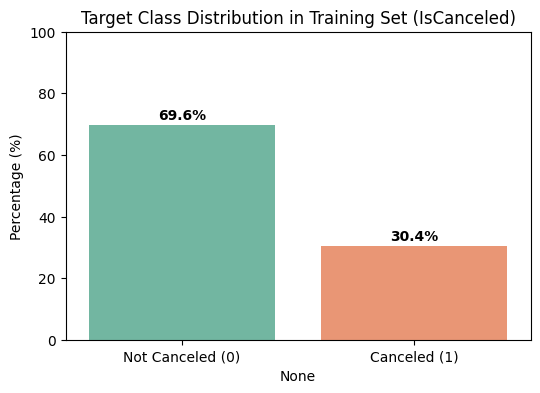

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Exact counts and percentages in training and testing sets
train_counts = y_train.value_counts()
train_props = y_train.value_counts(normalize=True) * 100

test_counts = y_test.value_counts()
test_props = y_test.value_counts(normalize=True) * 100

imbalance_df = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_props.round(2),
    'Test Count': test_counts,
    'Test (%)': test_props.round(2),
})
imbalance_df.index = ['Not Canceled (0)', 'Canceled (1)']
display(imbalance_df)

# 2. Imbalance ratio (Majority / Minority)
imbalance_ratio = train_counts.max() / train_counts.min()
print(f'Imbalance Ratio (Majority : Minority): {imbalance_ratio:.2f} : 1')

# 3. Quick visualization
plt.figure(figsize=(6, 4))
sns.barplot(
    x=imbalance_df.index,
    y=imbalance_df['Train (%)'],
    palette='Set2',
)
plt.title('Target Class Distribution in Training Set (IsCanceled)')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)
for i, v in enumerate(imbalance_df['Train (%)']):
  plt.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')
plt.show()

In [ ]:
# 1. Exact duplicate rows in X_train and X_test
train_dups = X_train.duplicated(keep=False)
test_dups = X_test.duplicated(keep=False)

print(f"Exact duplicate rows in X_train (all occurrences): {train_dups.sum()}")
print(f"Extra duplicate rows to drop in X_train: {X_train.duplicated().sum()}")
print(f"Exact duplicate rows in X_test (all occurrences): {test_dups.sum()}")
print(f"Extra duplicate rows to drop in X_test: {X_test.duplicated().sum()}")

# 2. Check if identical X_train rows have different IsCanceled labels (label noise)
train_xy = X_train.assign(IsCanceled=y_train)
conflicting_x = (
    train_xy.groupby(list(X_train.columns), dropna=False)["IsCanceled"].nunique()
    > 1
)
print(
    f"Unique feature combinations in X_train with conflicting IsCanceled labels:"
    f" {conflicting_x.sum()}"
)

# 3. Preview some duplicate groups in X_train (including target)
if train_dups.sum() > 0:
  display(
      train_xy[train_dups]
      .sort_values(by=list(X_train.columns[: min(5, len(X_train.columns))]))
      .head(15)
  )

Exact duplicate rows in X_train (all occurrences): 0
Extra duplicate rows to drop in X_train: 0
Exact duplicate rows in X_test (all occurrences): 0
Extra duplicate rows to drop in X_test: 0
Unique feature combinations in X_train with conflicting IsCanceled labels: 0


Lead Time - log transform it for KNN,SVM, linear reg,...

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

train_eda = X_train.copy()
train_eda['IsCanceled'] = y_train

# 1. Summary stats split by cancellation status
display(train_eda.groupby('IsCanceled')['LeadTime'].describe())

,count,mean,std,min,25%,50%,75%,max
IsCanceled,,,,,,,,
0,30472.0,67.910410,76.029797,0.0,9.0,40.0,104.0,518.0
1,13309.0,103.584567,93.139547,0.0,31.0,76.0,153.0,629.0


Date

In [ ]:
month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']
tmp = X_train.assign(y=y_train)
print(tmp.groupby("ArrivalDateMonth")["y"].agg(["mean", "count"]).reindex(month_order).round(3))

                   mean  count
ArrivalDateMonth              
January           0.281   2274
February          0.273   2907
March             0.283   3976
April             0.348   4179
May               0.325   4462
June              0.311   4126
July              0.336   4654
August            0.325   5411
September         0.256   3468
October           0.274   3472
November          0.251   2354
December          0.323   2498


In [ ]:
import pandas as pd

tmp = X_train.assign(y=y_train)
month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']

# 1. YEAR: does the cancellation rate drift between years?
print("By year:")
print(tmp.groupby("ArrivalDateYear")["y"].agg(["mean", "count"]).round(3))

# 2. WEEK NUMBER: is it redundant with month? (how many months does each week span?)
months_per_week = tmp.groupby("ArrivalDateWeekNumber")["ArrivalDateMonth"].nunique()
print("\nMonths spanned per week number:")
print(months_per_week.value_counts().sort_index())
print("Unique week numbers:", tmp["ArrivalDateWeekNumber"].nunique())

# 3. DAY OF MONTH: any pattern, or just noise around the base rate?
dom = tmp.groupby("ArrivalDateDayOfMonth")["y"].agg(["mean", "count"]).round(3)
print("\nDay of month: min / max rate:", dom["mean"].min(), "/", dom["mean"].max())
print("Overall base rate:", y_train.mean().round(3))
print(dom.T.to_string())

By year:
                  mean  count
ArrivalDateYear              
2015             0.224   5455
2016             0.296  21789
2017             0.341  16537

Months spanned per week number:
ArrivalDateMonth
1    36
2    17
Name: count, dtype: int64
Unique week numbers: 53

Day of month: min / max rate: 0.267 / 0.336
Overall base rate: 0.304
ArrivalDateDayOfMonth        1        2         3         4         5         6         7         8         9         10       11        12        13      14        15        16        17        18        19        20        21        22       23        24        25        26        27        28        29        30       31
mean                      0.326     0.31     0.317     0.293     0.281     0.287     0.314     0.324     0.302     0.299     0.29     0.299     0.298     0.3     0.315     0.317     0.309     0.288     0.267     0.296     0.289     0.321     0.29     0.306     0.273     0.321     0.318     0.327     0.328     0.336    0.278
cou

In [ ]:
import pandas as pd

month_mapping = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}

for d in (X_train, X_test):
    # Build from the original text column so re-running the cell doesn't break anything
    d["month"] = d["ArrivalDateMonth"].map(month_mapping)

print("Unmapped months (train, test):", X_train["month"].isna().sum(), X_test["month"].isna().sum())

# Fixed categories 1..12, so train and test always get the same 12 columns
for name in ("X_train", "X_test"):
    d = globals()[name]
    d["month"] = pd.Categorical(d["month"], categories=range(1, 13))

X_train = pd.get_dummies(X_train, columns=["month"], prefix="month", dtype=int)
X_test = pd.get_dummies(X_test, columns=["month"], prefix="month", dtype=int)

# Drop the raw date columns (year, week number and day of month are excluded on purpose)
drop_cols = ["ArrivalDateYear", "ArrivalDateMonth", "ArrivalDateDayOfMonth", "ArrivalDateWeekNumber"]
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

print([c for c in X_train.columns if c.startswith("month_")])

Unmapped months (train, test): 0 0
['month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']


Totalnights=Staysinweekends+weekdays and binary flag for zero nights

In [ ]:
X_train['TotalNights'] = (
    X_train['StaysInWeekendNights'] +
    X_train['StaysInWeekNights']
)

X_test['TotalNights'] = (
    X_test['StaysInWeekendNights'] +
    X_test['StaysInWeekNights']
)

X_train['WeekendOrNo'] = (
    X_train['StaysInWeekendNights'] > 0
).astype(int)

X_test['WeekendOrNo'] = (
    X_test['StaysInWeekendNights'] > 0
).astype(int)

In [ ]:
zero_nights_train = (X_train["TotalNights"] == 0).sum()
zero_nights_test = (X_test["TotalNights"] == 0).sum()

print(f"Number of bookings with 0 total nights in training set: {zero_nights_train}")
print(f"Number of bookings with 0 total nights in testing set: {zero_nights_test}")

Number of bookings with 0 total nights in training set: 234
Number of bookings with 0 total nights in testing set: 63


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Combine X_train and y_train safely without touching X_test
train_eda = X_train.copy()
train_eda['IsCanceled'] = y_train

# 1. Create a flag comparing TotalNights == 0 vs TotalNights > 0
train_eda['StayType'] = train_eda['TotalNights'].apply(
    lambda x: 'Zero Nights (TotalNights == 0)' if x == 0 else '1+ Nights'
)

# 2. Summary table: exact counts, cancellations, and cancellation rate
summary = (
    train_eda.groupby('StayType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .reset_index()
)
display(summary)

,StayType,total_bookings,canceled_count,cancellation_rate
0,1+ Nights,43547,13296,0.305325
1,Zero Nights (TotalNights == 0),234,13,0.055556


In [ ]:
X_train['IsZeroNights'] = (X_train['TotalNights'] == 0).astype(int)
X_test['IsZeroNights'] = (X_test['TotalNights'] == 0).astype(int)

In [ ]:
tmp = X_train.assign(y=y_train)
print(tmp.groupby("WeekendOrNo")["y"].agg(["mean", "count"]).round(3))
print(tmp.groupby(tmp["TotalNights"].clip(upper=8))["y"].agg(["mean", "count"]).round(3))

              mean  count
WeekendOrNo              
0            0.285  19199
1            0.319  24582
              mean  count
TotalNights              
0            0.056    234
1            0.226   8384
2            0.300   8954
3            0.320  11177
4            0.320   7821
5            0.307   3427
6            0.367   1319
7            0.377   1506
8            0.555    959


In [ ]:
X_train.drop(
    columns=['StaysInWeekendNights', 'StaysInWeekNights'],
    inplace=True
)
X_test.drop(
    columns=['StaysInWeekendNights', 'StaysInWeekNights'],
    inplace=True
)

Guests


In [ ]:
# 1. Inspect zero-adult bookings in train and test
print('Bookings with zero adults in df:', (df['Adults'] == 0).sum())
print(
    'Training bookings with zero adults:', (X_train['Adults'] == 0).sum()
)
print('Their IsCanceled distribution in training:')
print(y_train[X_train['Adults'] == 0].value_counts(dropna=False))

print(
    '\nTesting bookings with zero adults:', (X_test['Adults'] == 0).sum()
)
print('Their IsCanceled distribution in testing:')
print(y_test[X_test['Adults'] == 0].value_counts(dropna=False))

Bookings with zero adults in df: 390
Training bookings with zero adults: 316
Their IsCanceled distribution in training:
IsCanceled
0    234
1     82
Name: count, dtype: int64

Testing bookings with zero adults: 64
Their IsCanceled distribution in testing:
IsCanceled
0    45
1    19
Name: count, dtype: int64


In [ ]:
# 2. Combine train and test zero-adult rows to inspect IsCanceled
zero_adults = pd.concat([
    X_train[X_train['Adults'] == 0].assign(
        IsCanceled=y_train[X_train['Adults'] == 0]
    ),
    X_test[X_test['Adults'] == 0].assign(
        IsCanceled=y_test[X_test['Adults'] == 0]
    ),
])

print(
    zero_adults[['Adults', 'Children', 'Babies', 'IsCanceled']]
    .sort_values(['IsCanceled'])
    .to_string()
)

print(
    'Zero adults, children, and babies:',
    (
        (zero_adults['Adults'] == 0)
        & (zero_adults['Children'] == 0)
        & (zero_adults['Babies'] == 0)
    ).sum(),
)



       Adults  Children  Babies  IsCanceled
69642       0       2.0       0           0
67932       0       0.0       0           0
66730       0       2.0       0           0
68173       0       0.0       0           0
67917       0       0.0       0           0
50727       0       2.0       0           0
7120        0       0.0       0           0
74848       0       0.0       0           0
70967       0       0.0       0           0
55608       0       2.0       0           0
64171       0       0.0       0           0
42227       0       2.0       0           0
67097       0       0.0       0           0
56539       0       0.0       0           0
48926       0       2.0       0           0
63257       0       0.0       0           0
63204       0       0.0       0           0
55066       0       2.0       0           0
960         0       0.0       0           0
67483       0       0.0       0           0
50870       0       0.0       0           0
70982       0       0.0       0 

In [ ]:
no_guests = (zero_adults['Children'] == 0) & (zero_adults['Babies'] == 0)
print('\nCancellation rate by group within zero-adult bookings:')
print(
    'No guests cancellation rate:', zero_adults.loc[no_guests, 'IsCanceled'].mean()
)
print(
    'Guests present cancellation rate:',
    zero_adults.loc[~no_guests, 'IsCanceled'].mean(),
)


Cancellation rate by group within zero-adult bookings:
No guests cancellation rate: 0.11320754716981132
Guests present cancellation rate: 0.3755656108597285


In [ ]:
# 1. Fill any missing Children values with 0 before summing
X_train['Children'] = X_train['Children'].fillna(0)
X_test['Children'] = X_test['Children'].fillna(0)

# 2. Compute total_guests
X_train['total_guests'] = (
    X_train['Adults'] + X_train['Children'] + X_train['Babies']
)
X_test['total_guests'] = (
    X_test['Adults'] + X_test['Children'] + X_test['Babies']
)

# 3. Filter out rows where Adults == 0 OR total_guests == 0
# (Hotels require at least 1 adult per room)
train_mask = (X_train['Adults'] > 0) & (X_train['total_guests'] > 0)
test_mask = (X_test['Adults'] > 0) & (X_test['total_guests'] > 0)

X_train = X_train.loc[train_mask].copy()
y_train = y_train.loc[train_mask].copy()

X_test = X_test.loc[test_mask].copy()
y_test = y_test.loc[test_mask].copy()

# 4. Verify results
print('Invalid adult/guest rows in training:', (~train_mask).sum())
print('Invalid adult/guest rows in testing:', (~test_mask).sum())
print('Remaining training rows:', len(X_train))
print('Remaining testing rows:', len(X_test))

Invalid adult/guest rows in training: 316
Invalid adult/guest rows in testing: 64
Remaining training rows: 43465
Remaining testing rows: 12379


In [ ]:
guest_columns_to_drop = ['Adults', 'Children', 'Babies']

X_train.drop(columns=guest_columns_to_drop, inplace=True, errors='ignore')
X_test.drop(columns=guest_columns_to_drop, inplace=True, errors='ignore')

print("Remaining columns in X_train:", X_train.columns.tolist())

Remaining columns in X_train: ['LeadTime', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate', 'month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests']


Meal


,total_bookings,canceled_count,cancellation_rate
Meal,,,
BB,33508,9787,0.292080
SC,7595,2726,0.358920
HB,2352,712,0.302721
FB,10,2,0.200000


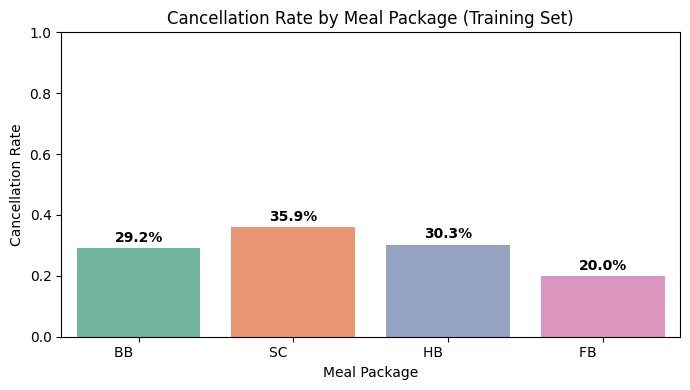

In [ ]:
# 1. Exact counts and cancellation rates per Meal package (on training set)
meal_summary = (
    pd.DataFrame({'Meal': X_train['Meal'], 'IsCanceled': y_train})
    .groupby('Meal')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)
display(meal_summary)

# 2. Proper visualization: Cancellation rate barplot
plt.figure(figsize=(7, 4))
sns.barplot(
    x=meal_summary.index,
    y=meal_summary['cancellation_rate'],
    hue=meal_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by Meal Package (Training Set)')
plt.xlabel('Meal Package')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(meal_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder


def one_hot_encode_cols(
    X_train: pd.DataFrame, X_test: pd.DataFrame, cols: list[str]
):
  X_train = X_train.copy()
  X_test = X_test.copy()

  present_cols = [c for c in cols if c in X_train.columns]
  if not present_cols:
    return X_train, X_test

  encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

  train_encoded = pd.DataFrame(
      encoder.fit_transform(X_train[present_cols]),
      columns=encoder.get_feature_names_out(present_cols),
      index=X_train.index,
  )
  test_encoded = pd.DataFrame(
      encoder.transform(X_test[present_cols]),
      columns=encoder.get_feature_names_out(present_cols),
      index=X_test.index,
  )

  X_train = pd.concat(
      [X_train.drop(columns=present_cols), train_encoded], axis=1
  )
  X_test = pd.concat([X_test.drop(columns=present_cols), test_encoded], axis=1)

  return X_train, X_test


# Example usage after dropping duplicates and splitting:
X_train, X_test = one_hot_encode_cols(X_train, X_test, ["Meal"])
print(
    "Encoded Meal columns:", [c for c in X_train.columns if c.startswith("Meal_")]
)

Encoded Meal columns: ['Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ']


In [ ]:
# Check all remaining columns, data types, and any remaining missing values
summary_df = pd.DataFrame({
    'dtype': X_train.dtypes,
    'train_nulls': X_train.isna().sum(),
    'test_nulls': X_test.isna().sum(),
    'unique_train': X_train.nunique(),
})

print(f'Total columns: {X_train.shape[1]}')
display(summary_df)

# Specifically list any remaining object/categorical columns
remaining_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print('\nRemaining categorical columns:', remaining_cat)

Total columns: 40


,dtype,train_nulls,test_nulls,unique_train
LeadTime,int64,0,0,449
Country,object,3,1,160
MarketSegment,object,0,0,8
DistributionChannel,object,0,0,5
IsRepeatedGuest,int64,0,0,2
PreviousCancellations,int64,0,0,10
PreviousBookingsNotCanceled,int64,0,0,66
ReservedRoomType,object,0,0,7
AssignedRoomType,object,0,0,8
BookingChanges,int64,0,0,17



Remaining categorical columns: ['Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType', 'ReservationStatus', 'ReservationStatusDate']


Country


In [ ]:
# All unique values (including missing), with counts
counts = X_train["Country"].value_counts(dropna=False)
print("Unique values:", X_train["Country"].nunique(dropna=False))
print(counts.to_string())          # to_string() prints every row, no "..." truncation

# Just the sorted list of codes
print(sorted(X_train["Country"].dropna().unique()))

Unique values: 161
Country
PRT    10849
FRA     5996
GBR     3684
DEU     3675
ESP     3082
ITA     2199
BEL     1336
BRA     1283
USA     1169
NLD     1125
CHE      947
IRL      857
AUT      633
CHN      581
SWE      463
POL      384
CN       383
NOR      342
ISR      317
RUS      313
AGO      261
DNK      260
ROU      234
AUS      233
FIN      227
TUR      159
LUX      154
JPN      143
HUN      129
MAR      122
ARG      117
KOR       94
CZE       87
GRC       87
IND       86
HRV       69
IRN       67
DZA       61
MEX       56
BGR       49
COL       45
SRB       41
ZAF       40
MOZ       40
UKR       38
NZL       38
EST       36
CHL       35
SAU       33
CYP       31
TUN       30
TWN       29
ARE       27
SVK       27
SVN       26
THA       25
LTU       24
SGP       24
EGY       22
NGA       19
URY       18
LBN       18
PER       18
IDN       17
LVA       16
ISL       16
ECU       16
VEN       15
PHL       15
KAZ       14
CPV       14
MYS       13
HKG       13
BLR       13
JOR       1

In [ ]:
print("CN rows in train:", (X_train["Country"] == "CN").sum())
print("CN rows in test: ", (X_test["Country"] == "CN").sum())

for d in (X_train, X_test):
    d["Country"] = d["Country"].replace({"CN": "CHN"})

CN rows in train: 383
CN rows in test:  121


Total unique countries in X_train: 160


,total_bookings,canceled_count,cancellation_rate
Country,,,
PRT,10849,4140,0.381602
FRA,5996,1265,0.210974
GBR,3684,1072,0.290988
DEU,3675,756,0.205714
ESP,3082,912,0.295912
ITA,2199,838,0.381082
BEL,1336,283,0.211826
BRA,1283,513,0.399844
USA,1169,335,0.286570


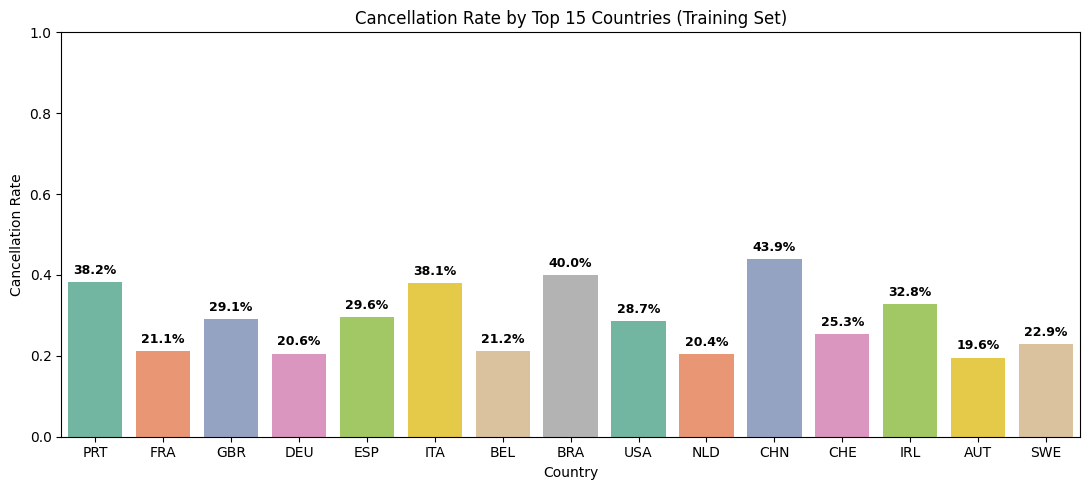

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Exact counts and cancellation rates per Country (on training set)
country_summary = (
    pd.DataFrame({
        'Country': X_train['Country'].fillna('Missing'),
        'IsCanceled': y_train,
    })
    .groupby('Country')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

print(f'Total unique countries in X_train: {len(country_summary)}')
display(country_summary.head(20))

# 2. Barplot of Top 15 countries by booking volume
top_n = 15
top_countries = country_summary.head(top_n)

plt.figure(figsize=(11, 5))
sns.barplot(
    x=top_countries.index,
    y=top_countries['cancellation_rate'],
    hue=top_countries.index,
    palette='Set2',
    legend=False,
)
plt.title(f'Cancellation Rate by Top {top_n} Countries (Training Set)')
plt.xlabel('Country')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(top_countries['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

Cancel rate by quarter: PRT (1) vs other countries (0)
group       0      1
date                
2015Q3  0.087  0.684
2015Q4  0.030  0.580
2016Q1  0.240  0.533
2016Q2  0.254  0.638
2016Q3  0.278  0.606
2016Q4  0.311  0.712
2017Q1  0.290  0.610
2017Q2  0.323  0.802
2017Q3  0.325  0.544
group      0     1
date              
2015Q3  2266  5141
2015Q4  2450  3825
2016Q1  3886  2895
2016Q2  6306  4854
2016Q3  7412  2968
2016Q4  6505  3314
2017Q1  5685  2693
2017Q2  8421  4025
2017Q3  5439  1245



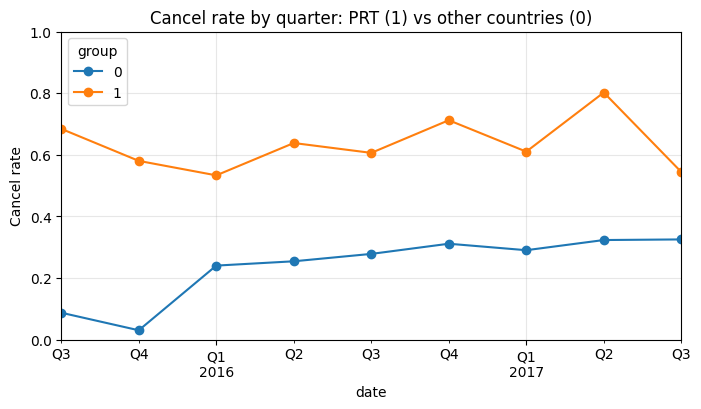

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv('/content/H2.csv')          # fresh copy
raw['Country'] = raw.Country.fillna('Unknown').astype(str).str.strip()

month_map = {m: i for i, m in enumerate(['January','February','March','April','May','June','July',
             'August','September','October','November','December'], 1)}
raw['date'] = pd.to_datetime(dict(year=raw.ArrivalDateYear,
                                  month=raw.ArrivalDateMonth.map(month_map),
                                  day=raw.ArrivalDateDayOfMonth))

def quarter_trend(data, flag, title):
    """flag = a 0/1 column that splits the bookings into two groups."""
    g = data.groupby([data.date.dt.to_period('Q'), flag.rename('group')]).IsCanceled
    rate  = g.mean().unstack().round(3)     # cancel rate per quarter and group
    count = g.size().unstack()              # bookings per quarter and group
    print(title); print(rate); print(count); print()
    ax = rate.plot(marker='o', figsize=(8, 4))
    ax.set_ylabel('Cancel rate'); ax.set_ylim(0, 1); ax.set_title(title); ax.grid(alpha=0.3)
    plt.show()

quarter_trend(raw, (raw.Country == 'PRT').astype(int),
              'Cancel rate by quarter: PRT (1) vs other countries (0)')

In [ ]:
tmp = df.loc[X_train.index].copy()
tmp["y"] = y_train
tmp["is_PRT"] = tmp["Country"] == "PRT"
print(tmp.groupby(["ArrivalDateYear", "is_PRT"])["y"].agg(["mean", "count"]).round(3))

                         mean  count
ArrivalDateYear is_PRT              
2015            False   0.022   2685
                True    0.423   2737
2016            False   0.284  16404
                True    0.333   5203
2017            False   0.322  13527
                True    0.430   2909


In [ ]:
# Filter out rows where Country is missing (in both X and y)
train_country_mask = X_train["Country"].notna()
test_country_mask = X_test["Country"].notna()

X_train = X_train.loc[train_country_mask].copy()
y_train = y_train.loc[train_country_mask].copy()

X_test = X_test.loc[test_country_mask].copy()
y_test = y_test.loc[test_country_mask].copy()

# Verify results
print("Missing Country rows in training:", X_train["Country"].isna().sum())
print("Missing Country rows in testing:", X_test["Country"].isna().sum())
print("Remaining training rows:", len(X_train))
print("Remaining testing rows:", len(X_test))

Missing Country rows in training: 0
Missing Country rows in testing: 0
Remaining training rows: 43462
Remaining testing rows: 12378


In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder


# 2. Fit the encoder on TRAIN only
country_encoder = OneHotEncoder(
    min_frequency=500,                      # lower to ~200 if CHN/BRA get lumped in
    handle_unknown="infrequent_if_exist",   # unseen test countries go to the infrequent bucket
    sparse_output=False,
)
country_train_arr = country_encoder.fit_transform(X_train[["Country"]])
country_test_arr = country_encoder.transform(X_test[["Country"]])

# 3. Inspect what got its own column and what was grouped
print("Own columns:", [c for c in country_encoder.categories_[0]
                       if c not in country_encoder.infrequent_categories_[0]])
print("Grouped as infrequent:", list(country_encoder.infrequent_categories_[0]))

# 4. Build DataFrames with the original index so the concat lines up
country_cols = country_encoder.get_feature_names_out(["Country"])
country_train_df = pd.DataFrame(country_train_arr, columns=country_cols, index=X_train.index)
country_test_df = pd.DataFrame(country_test_arr, columns=country_cols, index=X_test.index)

Own columns: ['AUT', 'BEL', 'BRA', 'CHE', 'CHN', 'DEU', 'ESP', 'FRA', 'GBR', 'IRL', 'ITA', 'NLD', 'PRT', 'USA']
Grouped as infrequent: ['ABW', 'AGO', 'AIA', 'ALB', 'AND', 'ARE', 'ARG', 'ARM', 'ASM', 'ATA', 'ATF', 'AUS', 'AZE', 'BEN', 'BFA', 'BGD', 'BGR', 'BHR', 'BIH', 'BLR', 'BOL', 'BRB', 'CAF', 'CHL', 'CIV', 'CMR', 'COL', 'COM', 'CPV', 'CRI', 'CUB', 'CYP', 'CZE', 'DMA', 'DNK', 'DOM', 'DZA', 'ECU', 'EGY', 'EST', 'ETH', 'FIN', 'FRO', 'GAB', 'GEO', 'GGY', 'GHA', 'GIB', 'GLP', 'GNB', 'GRC', 'GTM', 'GUY', 'HKG', 'HND', 'HRV', 'HUN', 'IDN', 'IMN', 'IND', 'IRN', 'IRQ', 'ISL', 'ISR', 'JAM', 'JEY', 'JOR', 'JPN', 'KAZ', 'KEN', 'KHM', 'KIR', 'KNA', 'KOR', 'KWT', 'LAO', 'LBN', 'LBY', 'LCA', 'LIE', 'LKA', 'LTU', 'LUX', 'LVA', 'MAC', 'MAR', 'MCO', 'MDV', 'MEX', 'MKD', 'MLI', 'MLT', 'MMR', 'MNE', 'MOZ', 'MRT', 'MUS', 'MYS', 'MYT', 'NAM', 'NCL', 'NGA', 'NIC', 'NOR', 'NZL', 'OMN', 'PAK', 'PAN', 'PER', 'PHL', 'POL', 'PRI', 'PRY', 'QAT', 'ROU', 'RUS', 'SAU', 'SEN', 'SGP', 'SLE', 'SLV', 'SRB', 'STP', 'SU

In [ ]:
# 5. Replace the raw Country column with the encoded ones
X_train = pd.concat([X_train.drop(columns="Country"), country_train_df], axis=1)
X_test = pd.concat([X_test.drop(columns="Country"), country_test_df], axis=1)

print("Encoded Country columns:", list(country_cols))
print("Total features:", X_train.shape[1])

Encoded Country columns: ['Country_AUT', 'Country_BEL', 'Country_BRA', 'Country_CHE', 'Country_CHN', 'Country_DEU', 'Country_ESP', 'Country_FRA', 'Country_GBR', 'Country_IRL', 'Country_ITA', 'Country_NLD', 'Country_PRT', 'Country_USA', 'Country_infrequent_sklearn']
Total features: 54


MarketSegment


In [ ]:
segments_counts = df["MarketSegment"].value_counts()

print("segments counts:")
print(segments_counts)

segments counts:
MarketSegment
Online TA        38748
Offline TA/TO    16747
Groups           13975
Direct            6093
Corporate         2986
Complementary      542
Aviation           237
Undefined            2
Name: count, dtype: int64


In [ ]:
# Training set for Undefined MarketSegment
undefined_train = X_train['MarketSegment'] == 'Undefined'

print("Training set — Undefined MarketSegment:")
print(y_train.loc[undefined_train].describe())
print("Number of rows:", undefined_train.sum())

# Test set for Undefined MarketSegment
undefined_test = X_test['MarketSegment'] == 'Undefined'

print("\nTest set — Undefined MarketSegment:")
print(y_test.loc[undefined_test].describe())
print("Number of rows:", undefined_test.sum())

Training set — Undefined MarketSegment:
count    1.0
mean     1.0
std      NaN
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: IsCanceled, dtype: float64
Number of rows: 1

Test set — Undefined MarketSegment:
count    1.0
mean     1.0
std      NaN
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: IsCanceled, dtype: float64
Number of rows: 1


In [ ]:
#drop undefined rows - both iscanceled = 1
train_mask = X_train['MarketSegment'] != 'Undefined'
test_mask = X_test['MarketSegment'] != 'Undefined'

X_train = X_train.loc[train_mask].copy()
y_train = y_train.loc[train_mask].copy()

X_test = X_test.loc[test_mask].copy()
y_test = y_test.loc[test_mask].copy()

# Verify removal
print('Undefined in train:', (X_train['MarketSegment'] == 'Undefined').sum())
print('Undefined in test:', (X_test['MarketSegment'] == 'Undefined').sum())
print('Remaining train rows:', len(X_train), '| Remaining test rows:', len(X_test))

Undefined in train: 0
Undefined in test: 0
Remaining train rows: 43461 | Remaining test rows: 12377


,total_bookings,canceled_count,cancellation_rate
MarketSegment,,,
Online TA,28258,10290,0.364145
Offline TA/TO,6053,1100,0.181728
Direct,4449,721,0.162059
Groups,2282,816,0.357581
Corporate,1819,214,0.117647
Complementary,419,44,0.105012
Aviation,181,40,0.220994


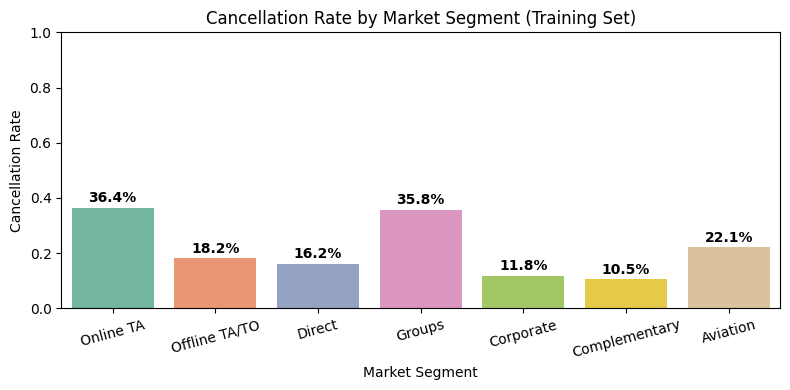

In [ ]:
# 1. Exact counts and cancellation rates per MarketSegment (on training set only)
market_summary = (
    pd.DataFrame(
        {'MarketSegment': X_train['MarketSegment'], 'IsCanceled': y_train}
    )
    .groupby('MarketSegment')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by MarketSegment
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by Market Segment (Training Set)')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# 1. Clean whitespace
X_train["MarketSegment"] = X_train["MarketSegment"].str.strip()
X_test["MarketSegment"] = X_test["MarketSegment"].str.strip()

# 2. Fit the encoder on TRAIN only
seg_encoder = OneHotEncoder(
    handle_unknown="ignore",    # a level unseen in train becomes all zeros in test
    sparse_output=False,
)
seg_train_arr = seg_encoder.fit_transform(X_train[["MarketSegment"]])
seg_test_arr = seg_encoder.transform(X_test[["MarketSegment"]])

# 3. Build DataFrames with the original index so the concat lines up
seg_cols = seg_encoder.get_feature_names_out(["MarketSegment"])
seg_train_df = pd.DataFrame(seg_train_arr, columns=seg_cols, index=X_train.index)
seg_test_df = pd.DataFrame(seg_test_arr, columns=seg_cols, index=X_test.index)

# 4. Replace the raw column with the encoded ones
X_train = pd.concat([X_train.drop(columns="MarketSegment"), seg_train_df], axis=1)
X_test = pd.concat([X_test.drop(columns="MarketSegment"), seg_test_df], axis=1)

print("Encoded MarketSegment columns:", list(seg_cols))
print("Total features:", X_train.shape[1])

Encoded MarketSegment columns: ['MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA']
Total features: 60


In [ ]:
# Check all current column names, data types, and remaining nulls/categoricals
print(f"Total columns: {X_train.shape[1]}")
print("Column names:", list(X_train.columns))

# Quick overview of any remaining object/categorical columns or missing values
remaining_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
remaining_nulls = X_train.columns[X_train.isna().any() | X_test.isna().any()].tolist()

print("\nRemaining categorical columns:", remaining_cat)
print("Columns with missing values (train or test):", remaining_nulls)

Total columns: 60
Column names: ['LeadTime', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate', 'month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'Country_AUT', 'Country_BEL', 'Country_BRA', 'Country_CHE', 'Country_CHN', 'Country_DEU', 'Country_ESP', 'Country_FRA', 'Country_GBR', 'Country_IRL', 'Country_ITA', 'Country_NLD', 'Country_PRT', 'Country_USA', 'Country_infrequent_sklearn', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'Ma

DistributionChannel


In [ ]:
channel_counts = df["DistributionChannel"].value_counts()

print("DistributionChannel:")
print(channel_counts)

DistributionChannel:
DistributionChannel
TA/TO        68945
Direct        6780
Corporate     3408
GDS            193
Undefined        4
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
DistributionChannel,,,
TA/TO,36335,12156,0.334553
Direct,4873,765,0.156987
Corporate,2108,274,0.129981
GDS,143,28,0.195804
Undefined,2,2,1.000000


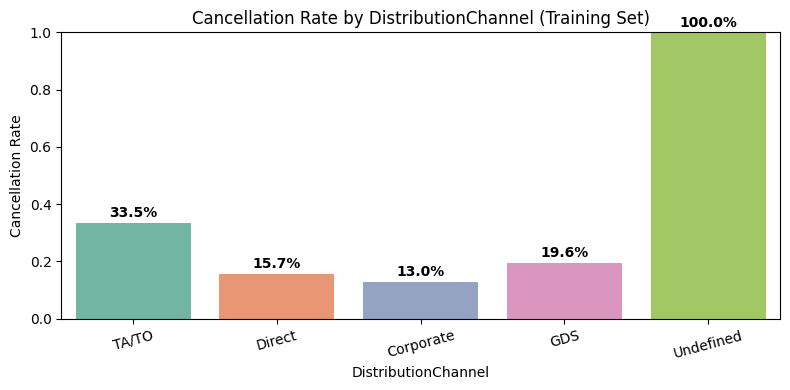

In [ ]:
# 1. Exact counts and cancellation rates per distribution (on training set only)
market_summary = (
    pd.DataFrame(
        {'DistributionChannel': X_train['DistributionChannel'], 'IsCanceled': y_train}
    )
    .groupby('DistributionChannel')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by DistributionChannel
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by DistributionChannel (Training Set)')
plt.xlabel('DistributionChannel')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
pd.crosstab(
    df["MarketSegment"],
    df["DistributionChannel"]
)

DistributionChannel,Corporate,Direct,GDS,TA/TO,Undefined
MarketSegment,,,,,
Aviation,227,0,0,10,0
Complementary,69,437,0,36,0
Corporate,2636,56,0,294,0
Direct,6,6048,1,37,1
Groups,240,177,0,13558,0
Offline TA/TO,198,6,45,16498,0
Online TA,32,56,147,38512,1
Undefined,0,0,0,0,2


In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OneHotEncoder

# Note: If you already encoded MarketSegment into MarketSegment_* columns in X_train,
# reconstruct the original label just for this diagnostic check:
if 'MarketSegment' in X_train.columns:
  ms_series = X_train['MarketSegment']
else:
  ms_cols = [c for c in X_train.columns if c.startswith('MarketSegment_')]
  ms_series = (
      X_train[ms_cols].idxmax(axis=1).str.replace('MarketSegment_', '', n=1)
  )

dc_series = X_train['DistributionChannel'].str.strip()

diag_df = pd.DataFrame(
    {'MarketSegment': ms_series, 'DistributionChannel': dc_series, 'IsCanceled': y_train}
)

# 1. Cancellation rate & count for every (MarketSegment, DistributionChannel) pair
breakdown = (
    diag_df.groupby(['MarketSegment', 'DistributionChannel'])['IsCanceled']
    .agg(bookings='count', cancel_rate='mean')
    .sort_values(['MarketSegment', 'bookings'], ascending=[True, False])
)
print('=== Cancellation Rate by MarketSegment x DistributionChannel ===')
display(breakdown)

# 2. Mutual Information with IsCanceled (higher = more predictive signal)
mi_ms = mutual_info_score(diag_df['MarketSegment'], diag_df['IsCanceled'])
mi_dc = mutual_info_score(diag_df['DistributionChannel'], diag_df['IsCanceled'])
print(f'\nMutual Information with IsCanceled:')
print(f'  MarketSegment alone:       {mi_ms:.5f}')
print(f'  DistributionChannel alone: {mi_dc:.5f}')

# 3. Does adding DistributionChannel to MarketSegment improve 5-fold CV ROC-AUC?
ohe = OneHotEncoder(handle_unknown='ignore')
X_ms_only = ohe.fit_transform(diag_df[['MarketSegment']])
X_both = ohe.fit_transform(diag_df[['MarketSegment', 'DistributionChannel']])

clf = LogisticRegression(max_iter=1000)
auc_ms = cross_val_score(
    clf, X_ms_only, diag_df['IsCanceled'], cv=5, scoring='roc_auc'
).mean()
auc_both = cross_val_score(
    clf, X_both, diag_df['IsCanceled'], cv=5, scoring='roc_auc'
).mean()

print(f'\n5-Fold CV ROC-AUC:')
print(f'  MarketSegment only:                  {auc_ms:.5f}')
print(f'  MarketSegment + DistributionChannel: {auc_both:.5f}')
print(f'  Net gain from DistributionChannel:   {auc_both - auc_ms:+.5f}')

=== Cancellation Rate by MarketSegment x DistributionChannel ===


bookings  cancel_rate
MarketSegment DistributionChannel                       
Aviation      Corporate                 171     0.228070
              TA/TO                      10     0.100000
Complementary Direct                    336     0.098214
              Corporate                  54     0.185185
              TA/TO                      29     0.034483
Corporate     Corporate                1670     0.119760
              TA/TO                     107     0.121495
              Direct                     42     0.023810
Direct        Direct                   4411     0.162321
              TA/TO                      32     0.031250
              Corporate                   4     0.750000
              GDS                         1     0.000000
              Undefined                   1     1.000000
Groups        TA/TO                    2120     0.374057
              Corporate                 124     0.096774
              Direct                     38     0.289474
Offline TA/TO TA/TO                    5948     0.183087
              Corporate                  67     0.074627
              GDS                        33     0.151515
              Direct                      5     0.200000
Online TA     TA/TO                   28089     0.365196
              GDS                       109     0.211009
              Direct                     41     0.073171
              Corporate                  18     0.277778
              Undefined                   1     1.000000


Mutual Information with IsCanceled:
  MarketSegment alone:       0.02188
  DistributionChannel alone: 0.01251

5-Fold CV ROC-AUC:
  MarketSegment only:                  0.58951
  MarketSegment + DistributionChannel: 0.59266
  Net gain from DistributionChannel:   +0.00315


In [ ]:
X_train.drop(columns=['DistributionChannel'], errors='ignore', inplace=True)
X_test.drop(columns=['DistributionChannel'], errors='ignore', inplace=True)

print("Remaining categorical columns:", X_train.select_dtypes(include=['object', 'category']).columns.tolist())
print("Columns with missing values:", X_train.columns[X_train.isna().any() | X_test.isna().any()].tolist())

Remaining categorical columns: ['ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType', 'ReservationStatus', 'ReservationStatusDate']
Columns with missing values: []


Guest History


Isrepeatedguest


In [ ]:
print(df["IsRepeatedGuest"].value_counts())

IsRepeatedGuest
0    77298
1     2032
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
IsRepeatedGuest,,,
0,42101,13067,0.310373
1,1360,158,0.116176


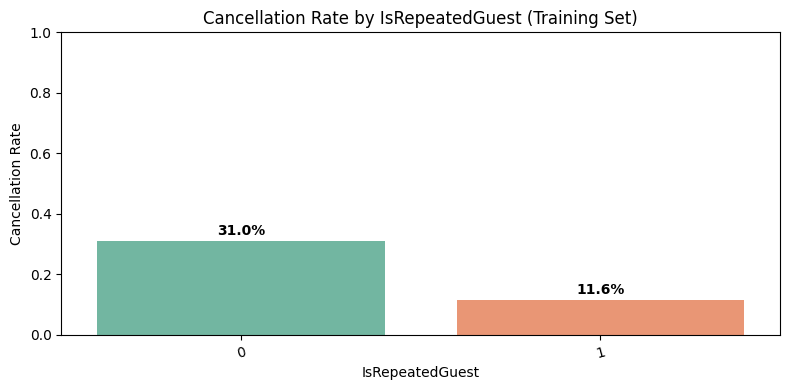

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'IsRepeatedGuest': X_train['IsRepeatedGuest'], 'IsCanceled': y_train}
    )
    .groupby('IsRepeatedGuest')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by IsRepeatedGuest (Training Set)')
plt.xlabel('IsRepeatedGuest')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
X_train.drop(columns=['IsRepeatedGuest'], errors='ignore', inplace=True)
X_test.drop(columns=['IsRepeatedGuest'], errors='ignore', inplace=True)

PreviousCancellations
!!!!!!!!!!!!!!!!!


In [ ]:
print(df["PreviousCancellations"].value_counts())

PreviousCancellations
0     73941
1      5155
2        72
3        51
11       35
4        25
6        22
5        16
13       12
21        1
Name: count, dtype: int64


In [ ]:
X_train.drop(columns=['PreviousCancellations'], errors='ignore', inplace=True)
X_test.drop(columns=['PreviousCancellations'], errors='ignore', inplace=True)

PreviousBookingNotCanceled
!!!!!!!!!!!!!!!


In [ ]:
import pandas as pd


def add_prev_not_canceled_flag(
    X_train: pd.DataFrame,
    X_test: pd.DataFrame,
    col: str = "PreviousBookingsNotCanceled",
    flag_name: str = "has_prev_not_canceled",
    drop_original: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
  X_train = X_train.copy()
  X_test = X_test.copy()

  if col not in X_train.columns:
    return X_train, X_test

  train_vals = pd.to_numeric(X_train[col], errors="coerce").fillna(0)
  test_vals = pd.to_numeric(X_test[col], errors="coerce").fillna(0)

  X_train[flag_name] = (train_vals > 0).astype(int)
  X_test[flag_name] = (test_vals > 0).astype(int)

  if drop_original:
    X_train = X_train.drop(columns=[col])
    X_test = X_test.drop(columns=[col, *( [col] if col in X_test.columns and False else [] )]) if False else X_test.drop(columns=[col], errors="ignore")

  return X_train, X_test


# Usage:
X_train, X_test = add_prev_not_canceled_flag(X_train, X_test)
print("Flag counts in train:\n", X_train["has_prev_not_canceled"].value_counts())
print("Original column still in X_train?", "PreviousBookingsNotCanceled" in X_train.columns)

Flag counts in train:
 has_prev_not_canceled
0    42218
1     1243
Name: count, dtype: int64
Original column still in X_train? False


ReservedRoomType


In [ ]:
print(df["ReservedRoomType"].value_counts())

ReservedRoomType
A                   62595
D                   11768
F                    1791
E                    1553
B                    1115
G                     484
C                      14
P                      10
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
ReservedRoomType,,,
A,31063,8978,0.289026
D,8739,3025,0.346149
F,1418,554,0.390691
E,1208,377,0.312086
B,636,193,0.303459
G,387,95,0.245478
C,10,3,0.300000


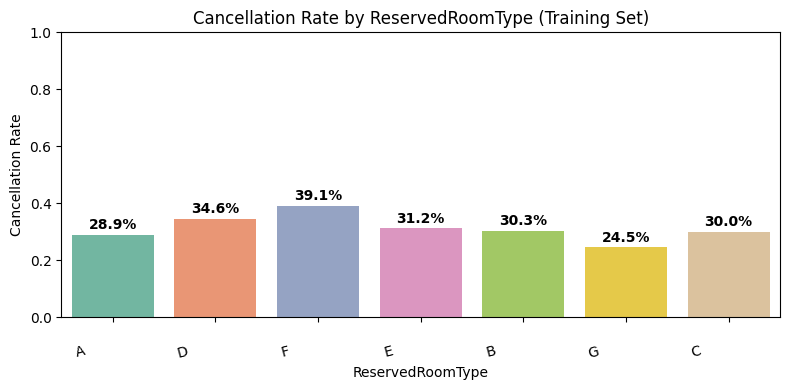

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'ReservedRoomType': X_train['ReservedRoomType'], 'IsCanceled': y_train}
    )
    .groupby('ReservedRoomType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by ReservedRoomType (Training Set)')
plt.xlabel('ReservedRoomType')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
X_train.drop(columns=['ReservedRoomType'], errors='ignore', inplace=True)
X_test.drop(columns=['ReservedRoomType'], errors='ignore', inplace=True)

AssignedRoomType


In [ ]:
X_train = X_train.drop(columns="AssignedRoomType")
X_test = X_test.drop(columns="AssignedRoomType")

BookingChnages


In [ ]:
print(df["BookingChanges"].value_counts())

BookingChanges
0     69062
1      7232
2      2244
3       467
4       194
5        46
6        31
7        19
8         9
14        5
9         4
13        3
15        3
10        3
11        2
20        1
17        1
21        1
12        1
18        1
16        1
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
BookingChanges,,,
0,36408,12057,0.331163
1,4842,644,0.133003
2,1638,404,0.246642
3,337,67,0.198813
4,142,33,0.232394
5,36,10,0.277778
6,22,6,0.272727
7,11,0,0.000000
8,7,2,0.285714


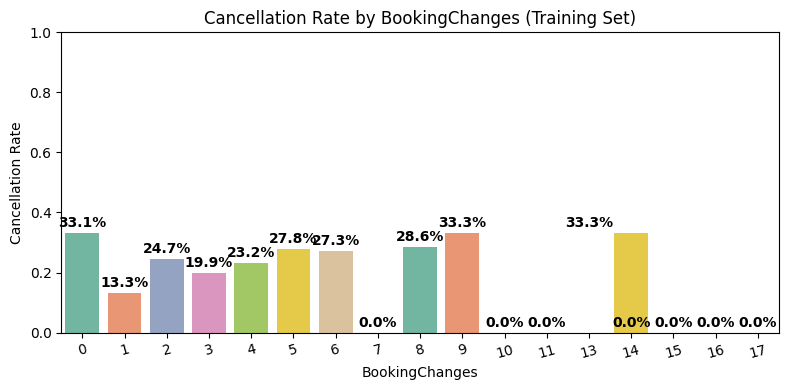

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'BookingChanges': X_train['BookingChanges'], 'IsCanceled': y_train}
    )
    .groupby('BookingChanges')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by BookingChanges (Training Set)')
plt.xlabel('BookingChanges')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
X_train.drop(columns=['BookingChanges'], errors='ignore', inplace=True)
X_test.drop(columns=['BookingChanges'], errors='ignore', inplace=True)

Deposit Type


In [ ]:
print(df["DepositType"].value_counts())

DepositType
No Deposit         66442
Non Refund         12868
Refundable            20
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
DepositType,,,
No Deposit,42647,12434,0.291556
Non Refund,801,782,0.976280
Refundable,13,9,0.692308


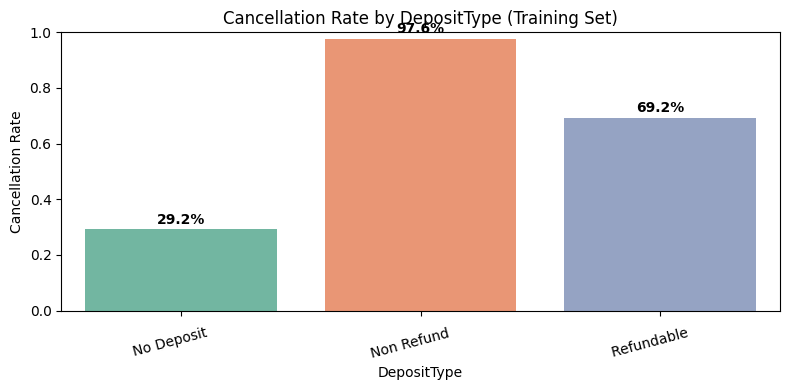

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'DepositType': X_train['DepositType'], 'IsCanceled': y_train}
    )
    .groupby('DepositType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by DepositType (Training Set)')
plt.xlabel('DepositType')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

raw = df.loc[X_train.index].copy()          # raw, unencoded columns for the training rows
raw["y"] = y_train
raw["DepositType"] = raw["DepositType"].str.strip()
raw["MarketSegment"] = raw["MarketSegment"].str.strip()
raw["Country"] = raw["Country"].fillna("Missing")


# 1. Where does Non Refund sit? Share of each deposit type by market segment
print(pd.crosstab(raw["DepositType"], raw["MarketSegment"], normalize="index").round(3))

# 3. Does it hold within each market segment?
print(raw.groupby(["MarketSegment", "DepositType"])["y"].agg(["mean", "count"]).round(3))

# 4. Top countries among Non Refund bookings
print(raw[raw["DepositType"] == "Non Refund"]["Country"].value_counts().head(10))

MarketSegment  Aviation  Complementary  Corporate  Direct  Groups  Offline TA/TO  Online TA
DepositType                                                                                
No Deposit        0.004           0.01      0.041   0.104   0.042          0.136      0.662
Non Refund        0.000           0.00      0.059   0.009   0.599          0.323      0.010
Refundable        0.000           0.00      0.231   0.077   0.000          0.154      0.538
                            mean  count
MarketSegment DepositType              
Aviation      No Deposit   0.221    181
Complementary No Deposit   0.105    419
Corporate     No Deposit   0.101   1769
              Non Refund   0.723     47
              Refundable   0.333      3
Direct        No Deposit   0.161   4441
              Non Refund   0.857      7
              Refundable   1.000      1
Groups        No Deposit   0.188   1802
              Non Refund   0.994    480
Offline TA/TO No Deposit   0.145   5792
              Non Re

In [ ]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

col = "DepositType"
if col in X_train.columns:
  X_train[col] = X_train[col].astype(str).str.strip()
  X_test[col] = X_test[col].astype(str).str.strip()

  dep_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
  dep_train_arr = dep_encoder.fit_transform(X_train[[col]])
  dep_test_arr = dep_encoder.transform(X_test[[col]])

  dep_cols = dep_encoder.get_feature_names_out([col])
  dep_train_df = pd.DataFrame(dep_train_arr, columns=dep_cols, index=X_train.index)
  dep_test_df = pd.DataFrame(dep_test_arr, columns=dep_cols, index=X_test.index)

  X_train = pd.concat([X_train.drop(columns=[col]), dep_train_df], axis=1)
  X_test = pd.concat([X_test.drop(columns=[col]), dep_test_df], axis=1)

  print("Encoded DepositType columns:", list(dep_cols))
  print("Total features:", X_train.shape[1])

Encoded DepositType columns: ['DepositType_No Deposit', 'DepositType_Non Refund', 'DepositType_Refundable']
Total features: 57


In [ ]:
X_train.drop(columns=['DepositType', 'is_non_refund'], errors='ignore', inplace=True)
X_test.drop(columns=['DepositType', 'is_non_refund'], errors='ignore', inplace=True)

print("Remaining columns:", X_train.columns.tolist())


Remaining columns: ['LeadTime', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate', 'month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB       ', 'Meal_FB       ', 'Meal_HB       ', 'Meal_SC       ', 'Country_AUT', 'Country_BEL', 'Country_BRA', 'Country_CHE', 'Country_CHN', 'Country_DEU', 'Country_ESP', 'Country_FRA', 'Country_GBR', 'Country_IRL', 'Country_ITA', 'Country_NLD', 'Country_PRT', 'Country_USA', 'Country_infrequent_sklearn', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA', 'DepositType_No Deposit', 'DepositType_Non Refund

Agent


,total_bookings,canceled_count,cancellation_rate
Agent,,,
9,23248,9416,0.405024
Other,8093,1827,0.225751
No_Agent,4493,675,0.150234
14,2693,455,0.168957
7,2651,346,0.130517
28,1212,74,0.061056
1,1071,432,0.403361


/tmp/ipykernel_1442/3647583304.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


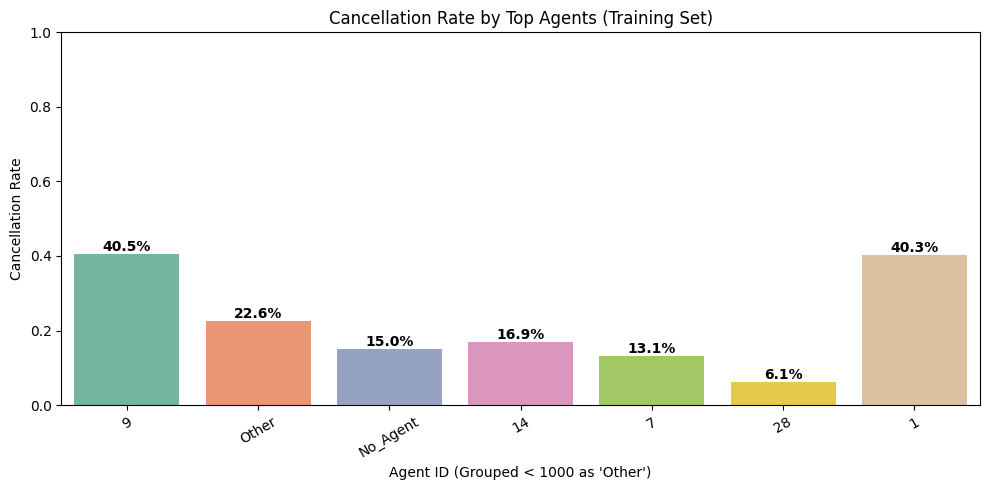

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Clean Agent values temporarily for inspection without modifying X_train
agent_clean = (
    X_train["Agent"]
    .fillna("No_Agent")
    .astype(str)
    .str.strip()
    .replace({"NULL": "No_Agent", "nan": "No_Agent"})
)

# Group rare agents (< 1000 bookings) into 'Other' so the table and chart stay readable
top_agents = agent_clean.value_counts()
major_agents = top_agents[top_agents >= 1000].index
agent_grouped = agent_clean.where(agent_clean.isin(major_agents), "Other")

# 1. Summary table sorted by total bookings
agent_summary = (
    pd.DataFrame({"Agent": agent_grouped, "IsCanceled": y_train})
    .groupby("Agent")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
    .sort_values("total_bookings", ascending=False)
)

display(agent_summary)

# 2. Bar plot of cancellation rates across top agents
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=agent_summary.index,
    y=agent_summary["cancellation_rate"],
    palette="Set2",
)
plt.title("Cancellation Rate by Top Agents (Training Set)")
plt.ylabel("Cancellation Rate")
plt.xlabel("Agent ID (Grouped < 1000 as 'Other')")
plt.ylim(0, 1.0)
plt.xticks(rotation=30)

for p in ax.patches:
  ax.annotate(
      f"{p.get_height()*100:.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

In [ ]:
print("Missing in Train / Test:", X_train["Agent"].isna().sum(), X_test["Agent"].isna().sum())
print(X_train["Agent"].describe())

Missing in Train / Test: 0 0
count           43461
unique            213
top                 9
freq            23248
Name: Agent, dtype: object


In [ ]:
for d in (X_train, X_test):
    d["Agent"] = (d["Agent"].astype(str).str.strip()
                  .replace({"NULL": "No_Agent", "nan": "No_Agent"}))

print("Unique agents in train:", X_train["Agent"].nunique())
print("Agents in test but not in train:", set(X_test["Agent"]) - set(X_train["Agent"]))

Unique agents in train: 213
Agents in test but not in train: {'25', '280', '70', '285', '397', '331', '144', '453', '197', '408', '90'}


In [ ]:
from sklearn.preprocessing import TargetEncoder

agent_te = TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=42)

# fit_transform on train: cross-fitted, so no row sees its own label
X_train["Agent_te"] = agent_te.fit_transform(X_train[["Agent"]], y_train).ravel()

# transform only on test: unseen agents fall back to the global mean
X_test["Agent_te"] = agent_te.transform(X_test[["Agent"]]).ravel()

X_train = X_train.drop(columns="Agent")
X_test = X_test.drop(columns="Agent")

print(X_train["Agent_te"].describe().round(3))

count    43461.000
mean         0.305
std          0.132
min          0.000
25%          0.155
50%          0.404
75%          0.405
max          1.000
Name: Agent_te, dtype: float64


In [ ]:
# Do the encoded values look sensible? Expect a spread from low (~0.07) to high (~0.74)
print(X_train["Agent_te"].round(2).value_counts().head(10))
print("Train mean:", X_train["Agent_te"].mean().round(3), "| y_train mean:", y_train.mean().round(3))

Agent_te
0.40    14369
0.41     9861
0.15     4541
0.13     2287
0.17     2252
0.06     1278
0.12      827
0.31      751
0.18      718
0.10      569
Name: count, dtype: int64
Train mean: 0.305 | y_train mean: 0.304


Company


=== Binary Comparison: No Company vs. Has Company ===


,total_bookings,canceled_count,cancellation_rate
Booking_Type,,,
Has Company (Corporate),2248,276,0.122776
No Company (NULL),41213,12949,0.314197



=== Top Individual Companies (>= 100 bookings in Train) ===


,total_bookings,canceled_count,cancellation_rate
Company,,,
No_Company,41213,12949,0.314197
Other_Company,1108,159,0.143502
40,678,53,0.078171
45,194,21,0.108247
153,164,38,0.231707
219,104,5,0.048077


/tmp/ipykernel_1442/3645883580.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(
/tmp/ipykernel_1442/3645883580.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

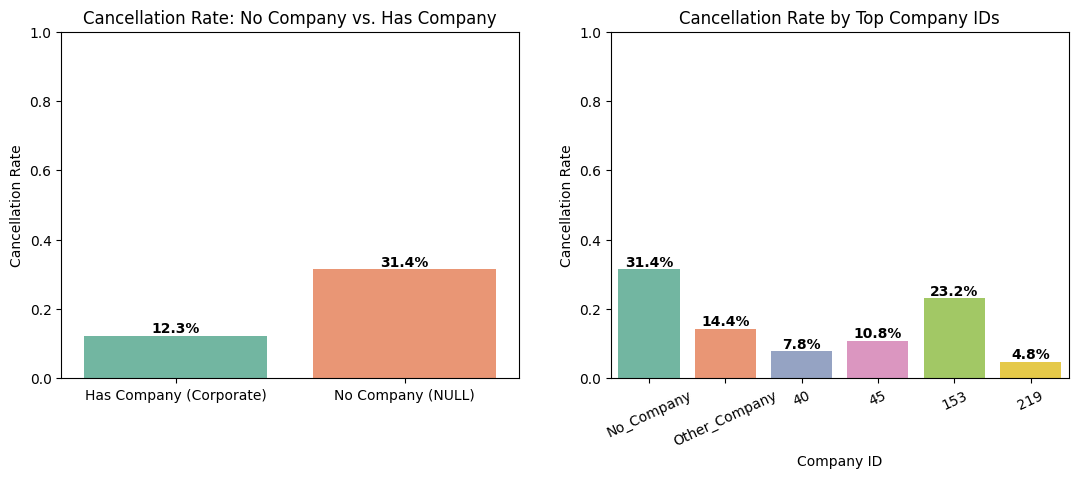

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Clean literal 'NULL' and missing values temporarily on X_train
company_clean = (
    X_train["Company"]
    .fillna("No_Company")
    .astype(str)
    .str.strip()
    .replace({"NULL": "No_Company", "nan": "No_Company"})
)

# 2. Check Binary Split: No Company ('NULL') vs. Has Company (Any Corporate ID)
has_company = (company_clean != "No_Company").map(
    {False: "No Company (NULL)", True: "Has Company (Corporate)"}
)
binary_summary = (
    pd.DataFrame({"Booking_Type": has_company, "IsCanceled": y_train})
    .groupby("Booking_Type")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)
print("=== Binary Comparison: No Company vs. Has Company ===")
display(binary_summary)

# 3. Check Top Individual Company IDs (to see if specific IDs differ or all behave similarly)
top_companies = company_clean.value_counts()
major_companies = top_companies[top_companies >= 100].index
company_grouped = company_clean.where(
    company_clean.isin(major_companies), "Other_Company"
)

detail_summary = (
    pd.DataFrame({"Company": company_grouped, "IsCanceled": y_train})
    .groupby("Company")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
    .sort_values("total_bookings", ascending=False)
)
print("\n=== Top Individual Companies (>= 100 bookings in Train) ===")
display(detail_summary)

# 4. Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot A: Binary (Has Company vs No Company)
ax1 = sns.barplot(
    x=binary_summary.index,
    y=binary_summary["cancellation_rate"],
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Cancellation Rate: No Company vs. Has Company")
axes[0].set_ylabel("Cancellation Rate")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 1.0)
for p in ax1.patches:
  ax1.annotate(
      f"{p.get_height()*100:.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

# Plot B: Top Companies
ax2 = sns.barplot(
    x=detail_summary.index,
    y=detail_summary["cancellation_rate"],
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate by Top Company IDs")
axes[1].set_ylabel("Cancellation Rate")
axes[1].set_xlabel("Company ID")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=25)
for p in ax2.patches:
  ax2.annotate(
      f"{p.get_height()*100:.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt

In [ ]:
for d in (X_train, X_test):
    company_clean = (
        d["Company"]
        .fillna("No_Company")
        .astype(str)
        .str.strip()
        .replace({"NULL": "No_Company", "nan": "No_Company"})
    )
    d["has_company"] = (company_clean != "No_Company").astype(int)

X_train = X_train.drop(columns=["Company"])
X_test = X_test.drop(columns=["Company"])

print("Train has_company distribution:\n", X_train["has_company"].value_counts())

Train has_company distribution:
 has_company
0    41213
1     2248
Name: count, dtype: int64


DaysInwaitinglist


=== DaysInWaitingList Summary (Train) ===
count    43461.000000
mean         1.079013
std         12.258071
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        391.000000
Name: DaysInWaitingList, dtype: float64

Exact 0 vs. > 0 counts:
DaysInWaitingList
0 days      42847
> 0 days      614
Name: count, dtype: int64

Top 10 most frequent values:
DaysInWaitingList
0     42847
63       40
87       22
44       20
48       19
58       19
15       18
27       16
38       16
77       15
Name: count, dtype: int64

=== Cancellation Rate by Waiting List Group (Train) ===


,total_bookings,canceled_count,cancellation_rate
Wait_Group,,,
0 days,42847,12978,0.302892
1-30 days,136,71,0.522059
31-90 days,326,118,0.361963
> 90 days,152,58,0.381579


/tmp/ipykernel_1442/1041262822.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


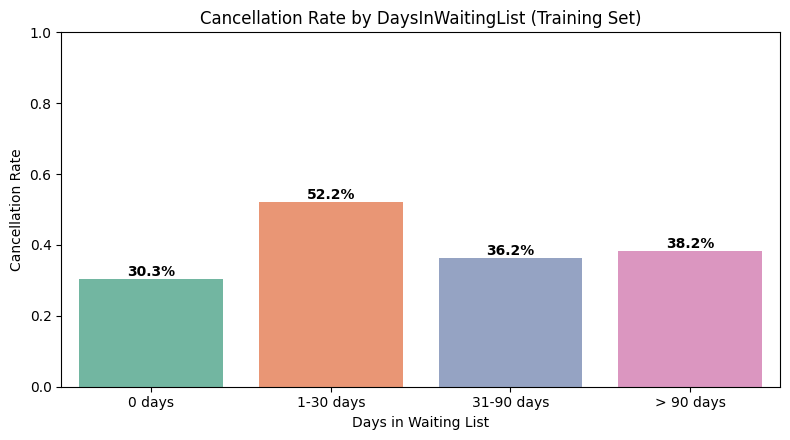

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Basic distribution & zero-inflation check
print("=== DaysInWaitingList Summary (Train) ===")
print(X_train["DaysInWaitingList"].describe())
print("\nExact 0 vs. > 0 counts:")
print((X_train["DaysInWaitingList"] > 0).value_counts().rename({False: "0 days", True: "> 0 days"}))

# 2. Top most frequent exact values
print("\nTop 10 most frequent values:")
print(X_train["DaysInWaitingList"].value_counts().head(10))

# 3. Cancellation rate comparison: 0 days vs. binned > 0 days
wait_bins = pd.cut(
    X_train["DaysInWaitingList"],
    bins=[-1, 0, 30, 90, X_train["DaysInWaitingList"].max()],
    labels=["0 days", "1-30 days", "31-90 days", "> 90 days"],
)

wait_summary = (
    pd.DataFrame({"Wait_Group": wait_bins, "IsCanceled": y_train})
    .groupby("Wait_Group", observed=False)["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)

print("\n=== Cancellation Rate by Waiting List Group (Train) ===")
display(wait_summary)

# 4. Plot cancellation rate across waiting groups
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    x=wait_summary.index,
    y=wait_summary["cancellation_rate"],
    palette="Set2",
)
plt.title("Cancellation Rate by DaysInWaitingList (Training Set)")
plt.ylabel("Cancellation Rate")
plt.xlabel("Days in Waiting List")
plt.ylim(0, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
X_train = X_train.drop(columns="DaysInWaitingList")
X_test = X_test.drop(columns="DaysInWaitingList")

CustomerType


In [ ]:
# Get the count and frequency of each unique value in the Meal column
cusType_counts = df["CustomerType"].value_counts()

print("Customer Type value counts:")
print(cusType_counts)

Customer Type value counts:
CustomerType
Transient          44184
Transient-Party     6914
Contract            1459
Group                267
Name: count, dtype: int64


,total_bookings,canceled_count,cancellation_rate
CustomerType,,,
Transient,36157,11885,0.328705
Transient-Party,5913,1007,0.170303
Contract,1176,312,0.265306
Group,215,21,0.097674


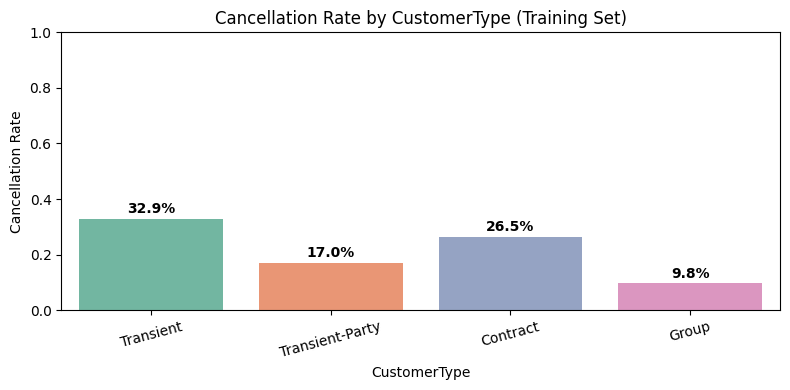

In [ ]:
# 1. Exact counts and cancellation rates per IsRepeatedGuest (on training set only)
market_summary = (
    pd.DataFrame(
        {'CustomerType': X_train['CustomerType'], 'IsCanceled': y_train}
    )
    .groupby('CustomerType')['IsCanceled']
    .agg(
        total_bookings='count',
        canceled_count='sum',
        cancellation_rate='mean',
    )
    .sort_values('total_bookings', ascending=False)
)

display(market_summary)

# 2. Barplot of cancellation rates by IsRepeatedGuest
plt.figure(figsize=(8, 4))
sns.barplot(
    x=market_summary.index,
    y=market_summary['cancellation_rate'],
    hue=market_summary.index,
    palette='Set2',
    legend=False,
)
plt.title('Cancellation Rate by CustomerType (Training Set)')
plt.xlabel('CustomerType')
plt.ylabel('Cancellation Rate')
plt.ylim(0, 1.0)
for i, v in enumerate(market_summary['cancellation_rate']):
  plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

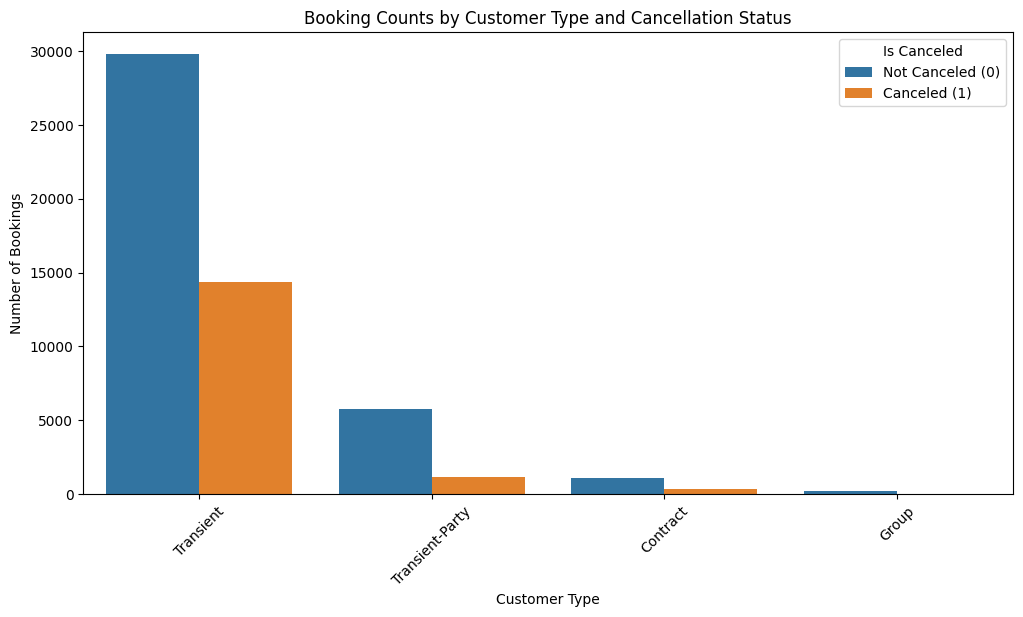

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='CustomerType', hue='IsCanceled')

plt.title('Booking Counts by Customer Type and Cancellation Status')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='Is Canceled', labels=['Not Canceled (0)', 'Canceled (1)'])
plt.show()

In [ ]:
for data in [X_train, X_test]:
    cust = data["CustomerType"].astype(str).str.strip()
    data["CustomerType_Transient_Party"] = (cust == "Transient-Party").astype(int)
    data["CustomerType_Contract"] = (cust == "Contract").astype(int)
    data["CustomerType_Group"] = (cust == "Group").astype(int)
    data.drop(columns=["CustomerType"], inplace=True)

ADR


=== ADR Summary (Train) ===
count    43461.000000
mean       111.163967
std         41.826675
min          0.000000
25%         84.050000
50%        105.370000
75%        134.000000
max        451.500000
Name: ADR, dtype: float64

Unique ADR values: 4804 out of 43461 rows
Zero ADR bookings (ADR == 0): 783
Negative ADR bookings (ADR < 0): 0

Top 10 most frequent ADR values:
ADR
75.0     827
65.0     810
0.0      783
95.0     573
90.0     528
99.0     512
126.0    499
85.0     487
108.0    485
120.0    465
Name: count, dtype: int64

Top 5 highest ADR values (outlier check):
[451.5  375.5  372.33 365.   352.5 ]

=== Cancellation Rate by ADR Bracket (Train) ===


,total_bookings,canceled_count,cancellation_rate
ADR_Bracket,,,
<= 0 (Free/Promo),783,77,0.098340
0-75,6425,1478,0.230039
75-100,12647,3636,0.287499
100-125,9651,3086,0.319760
125-150,7343,2603,0.354487
150-200,5280,1862,0.352652
> 200,1332,483,0.362613


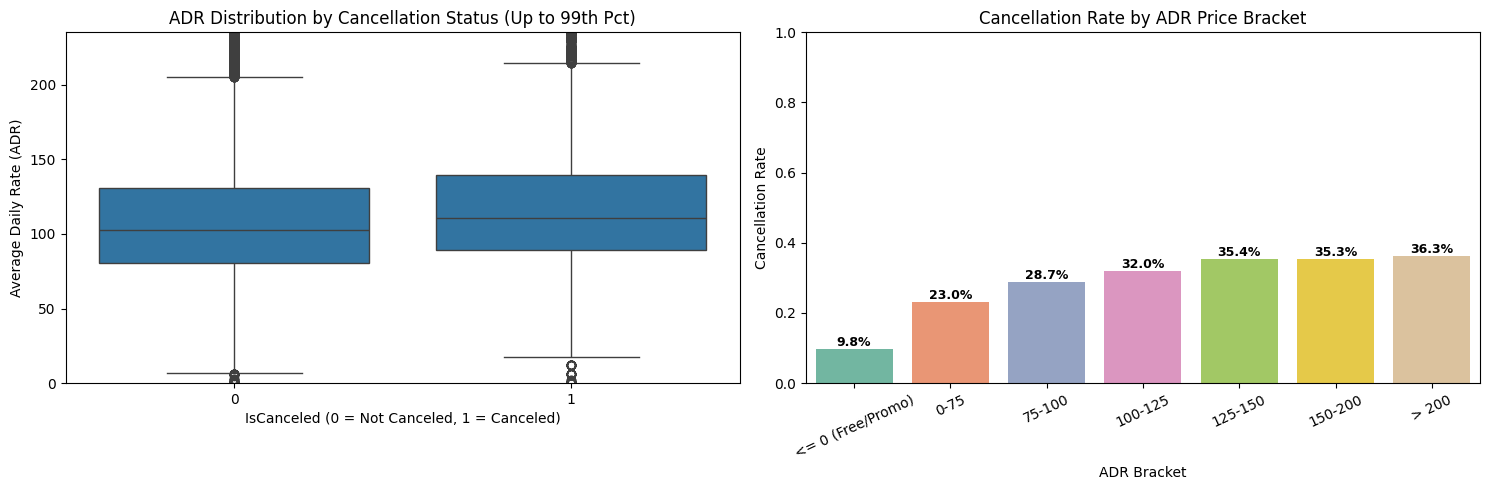

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Unique values & distribution summary (Training Set)
print("=== ADR Summary (Train) ===")
print(X_train["ADR"].describe())
print(f"\nUnique ADR values: {X_train['ADR'].nunique()} out of {len(X_train)} rows")
print(f"Zero ADR bookings (ADR == 0): {(X_train['ADR'] == 0).sum()}")
print(f"Negative ADR bookings (ADR < 0): {(X_train['ADR'] < 0).sum()}")
print("\nTop 10 most frequent ADR values:")
print(X_train["ADR"].value_counts().head(10))
print("\nTop 5 highest ADR values (outlier check):")
print(X_train["ADR"].nlargest(5).values)

# 2. Effect on IsCanceled across ADR price brackets
adr_bins = [-float("inf"), 0, 75, 100, 125, 150, 200, float("inf")]
adr_labels = ["<= 0 (Free/Promo)", "0-75", "75-100", "100-125", "125-150", "150-200", "> 200"]

adr_summary = (
    pd.DataFrame({
        "ADR_Bracket": pd.cut(X_train["ADR"], bins=adr_bins, labels=adr_labels),
        "IsCanceled": y_train,
    })
    .groupby("ADR_Bracket", observed=False)["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)

print("\n=== Cancellation Rate by ADR Bracket (Train) ===")
display(adr_summary)

# 3. Side-by-side visualization: Distribution + Binned Cancellation Rate
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Boxplot capped at 99th percentile so extreme outliers don't squash the box
train_plot = pd.DataFrame({"ADR": X_train["ADR"], "IsCanceled": y_train})
sns.boxplot(data=train_plot, x="IsCanceled", y="ADR", ax=axes[0])
axes[0].set_ylim(0, X_train["ADR"].quantile(0.99))
axes[0].set_title("ADR Distribution by Cancellation Status (Up to 99th Pct)")
axes[0].set_xlabel("IsCanceled (0 = Not Canceled, 1 = Canceled)")
axes[0].set_ylabel("Average Daily Rate (ADR)")

# Right: Cancellation rate by ADR bracket
ax_bar = sns.barplot(
    x=adr_summary.index,
    y=adr_summary["cancellation_rate"],
    hue=adr_summary.index,
    palette="Set2",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate by ADR Price Bracket")
axes[1].set_xlabel("ADR Bracket")
axes[1].set_ylabel("Cancellation Rate")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=25)

for p in ax_bar.patches:
    ax_bar.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
adr_cap = X_train["ADR"].quantile(0.999)

for data in [X_train, X_test]:
    data["is_free_stay"] = (data["ADR"] == 0).astype(int)
    data["ADR"] = data["ADR"].clip(lower=0, upper=adr_cap)

print("Train ADR min/max:", X_train["ADR"].min(), "/", X_train["ADR"].max())
print("Test ADR min/max:", X_test["ADR"].min(), "/", X_test["ADR"].max())

Train ADR min/max: 0.0 / 295.0
Test ADR min/max: 0.0 / 295.0


In [ ]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def evaluate_adr_variant(
    X_tr: pd.DataFrame,
    X_te: pd.DataFrame,
    y_tr: pd.Series,
    y_te: pd.Series,
    use_adr_zero_flag: bool,
    label: str,
) -> dict[str, float]:
  X_tr = X_tr.copy()
  X_te = X_te.copy()

  # Guardrail: drop any stray object/string columns if any were left unencoded
  obj_cols = X_tr.select_dtypes(include=["object", "string"]).columns.tolist()
  if obj_cols:
    X_tr = X_tr.drop(columns=obj_cols)
    X_te = X_te.drop(columns=obj_cols, errors="ignore")

  if use_adr_zero_flag and "ADR" in X_tr.columns:
    tr_adr = pd.to_numeric(X_tr["ADR"], errors="coerce")
    te_adr = pd.to_numeric(X_te["ADR"], errors="coerce")

    # Flag == 1 only when ADR is explicitly 0 (not NaN)
    X_tr["adr_is_zero"] = (tr_adr == 0).fillna(False).astype(int)
    X_te["adr_is_zero"] = (te_adr == 0).fillna(False).astype(int)

    X_tr = X_tr.drop(columns=["ADR"])
    X_te = X_te.drop(columns=["ADR"], errors="ignore")

  model = HistGradientBoostingClassifier(
      max_iter=300,
      learning_rate=0.05,
      random_state=42,
  )
  model.fit(X_tr, y_tr)

  y_pred = model.predict(X_te)
  y_proba = model.predict_proba(X_te)[:, 1]

  return {
      "variant": label,
      "n_features": X_tr.shape[1],
      "roc_auc": roc_auc_score(y_te, y_proba),
      "f1": f1_score(y_te, y_pred),
      "accuracy": accuracy_score(y_te, y_pred),
  }


results = [
    evaluate_adr_variant(
        X_train, X_test, y_train, y_test, use_adr_zero_flag=False, label="Keep raw ADR"
    ),
    evaluate_adr_variant(
        X_train, X_test, y_train, y_test, use_adr_zero_flag=True, label="Drop ADR + adr_is_zero flag"
    ),
]

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                    variant  n_features  roc_auc       f1  accuracy
               Keep raw ADR          56 0.896227 0.708445  0.824836
Drop ADR + adr_is_zero flag          56 0.891864 0.697725  0.819666


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def evaluate_adr_transform(
    X_tr: pd.DataFrame,
    X_te: pd.DataFrame,
    y_tr: pd.Series,
    y_te: pd.Series,
    mode: str,
    cap_quantile: float = 0.99,
) -> dict[str, float | int | str]:
  X_tr = X_tr.copy()
  X_te = X_te.copy()

  # Guardrail: drop any stray object/string columns if any were left unencoded
  obj_cols = X_tr.select_dtypes(include=["object", "string"]).columns.tolist()
  if obj_cols:
    X_tr = X_tr.drop(columns=obj_cols)
    X_te = X_te.drop(columns=obj_cols, errors="ignore")

  if "ADR" in X_tr.columns:
    tr_adr = pd.to_numeric(X_tr["ADR"], errors="coerce")
    te_adr = pd.to_numeric(X_te["ADR"], errors="coerce")

    if mode == "cap":
      # Fit upper bound on X_train ONLY to avoid test leakage
      upper_bound = tr_adr.quantile(cap_quantile)
      X_tr["ADR"] = tr_adr.clip(upper=upper_bound)
      X_te["ADR"] = te_adr.clip(upper=upper_bound)
      label = f"ADR capped at {int(cap_quantile * 100)}th pct ({upper_bound:.2f})"

    elif mode == "log":
      # Clip below 0 before log1p so negative/zero ADRs don't produce NaNs
      X_tr["ADR"] = np.log1p(tr_adr.clip(lower=0.0))
      X_te["ADR"] = np.log1p(te_adr.clip(lower=0.0))
      label = "ADR log1p (clipped >= 0)"

    else:
      raise ValueError(f"Unsupported mode: {mode}")
  else:
    label = f"ADR missing ({mode})"

  model = HistGradientBoostingClassifier(
      max_iter=300,
      learning_rate=0.05,
      random_state=42,
  )
  model.fit(X_tr, y_tr)

  y_pred = model.predict(X_te)
  y_proba = model.predict_proba(X_te)[:, 1]

  return {
      "variant": label,
      "n_features": X_tr.shape[1],
      "roc_auc": roc_auc_score(y_te, y_proba),
      "f1": f1_score(y_te, y_pred),
      "accuracy": accuracy_score(y_te, y_pred),
  }


results = [
    evaluate_adr_transform(
        X_train, X_test, y_train, y_test, mode="cap", cap_quantile=0.99
    ),
    evaluate_adr_transform(X_train, X_test, y_train, y_test, mode="log"),
]

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                        variant  n_features  roc_auc       f1  accuracy
ADR capped at 99th pct (235.00)          56 0.897703 0.712718  0.826614
       ADR log1p (clipped >= 0)          56 0.896227 0.708445  0.824836


In [ ]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def evaluate_raw_adr_plus_zero_flag(
    X_tr: pd.DataFrame,
    X_te: pd.DataFrame,
    y_tr: pd.Series,
    y_te: pd.Series,
    label: str = "Raw ADR + adr_is_zero flag",
) -> dict[str, float | int | str]:
  X_tr = X_tr.copy()
  X_te = X_te.copy()

  # Guardrail: drop any stray object/string columns if any were left unencoded
  obj_cols = X_tr.select_dtypes(include=["object", "string"]).columns.tolist()
  if obj_cols:
    X_tr = X_tr.drop(columns=obj_cols)
    X_te = X_te.drop(columns=obj_cols, errors="ignore")

  if "ADR" in X_tr.columns:
    tr_adr = pd.to_numeric(X_tr["ADR"], errors="coerce")
    te_adr = pd.to_numeric(X_te["ADR"], errors="coerce")

    X_tr["ADR"] = tr_adr
    X_te["ADR"] = te_adr
    X_tr["adr_is_zero"] = (tr_adr == 0).fillna(False).astype(int)
    X_te["adr_is_zero"] = (te_adr == 0).fillna(False).astype(int)

  model = HistGradientBoostingClassifier(
      max_iter=300,
      learning_rate=0.05,
      random_state=42,
  )
  model.fit(X_tr, y_tr)

  y_pred = model.predict(X_te)
  y_proba = model.predict_proba(X_te)[:, 1]

  return {
      "variant": label,
      "n_features": X_tr.shape[1],
      "roc_auc": roc_auc_score(y_te, y_proba),
      "f1": f1_score(y_te, y_pred),
      "accuracy": accuracy_score(y_te, y_pred),
  }


result_df = pd.DataFrame([
    evaluate_raw_adr_plus_zero_flag(X_train, X_test, y_train, y_test)
])
print(result_df.to_string(index=False))

                   variant  n_features  roc_auc       f1  accuracy
Raw ADR + adr_is_zero flag          57 0.896227 0.708445  0.824836


In [ ]:
X_train = X_train.drop(columns="ADR")
X_test = X_test.drop(columns="ADR")

In [ ]:
X_train.drop(columns=["is_free_stay"])
X_test.drop(columns=["is_free_stay"])

,LeadTime,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,month_1,month_2,month_3,month_4,month_5,...,MarketSegment_Online TA,DepositType_No Deposit,DepositType_Non Refund,DepositType_Refundable,Agent_te,has_company,has_prev_not_canceled,CustomerType_Transient_Party,CustomerType_Contract,CustomerType_Group
67326,8,0,2,Check-Out,2017-03-12,0,0,1,0,0,...,0.0,1.0,0.0,0.0,0.150254,0,0,0,0,0
8030,72,0,1,Canceled,2016-01-20,0,0,1,0,0,...,1.0,1.0,0.0,0.0,0.405019,0,0,0,0,0
44282,2,0,0,Check-Out,2016-02-24,0,1,0,0,0,...,0.0,1.0,0.0,0.0,0.061110,0,0,0,0,0
17639,267,0,0,Canceled,2016-02-09,0,0,0,0,0,...,0.0,0.0,1.0,0.0,0.206098,0,0,0,0,0
63416,197,0,0,Check-Out,2016-12-26,0,0,0,0,0,...,0.0,1.0,0.0,0.0,0.320632,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64969,33,0,2,Check-Out,2017-01-28,1,0,0,0,0,...,1.0,1.0,0.0,0.0,0.405019,0,0,0,0,0
49058,0,0,0,Check-Out,2016-05-17,0,0,0,0,1,...,0.0,1.0,0.0,0.0,0.250632,0,0,0,0,0
36610,0,0,0,Check-Out,2016-01-07,1,0,0,0,0,...,0.0,1.0,0.0,0.0,0.150254,1,1,0,0,0
37602,0,0,1,Check-Out,2017-03-22,0,0,1,0,0,...,0.0,1.0,0.0,0.0,0.150254,1,1,0,0,0


RequiredCarParkingSpaces



In [ ]:
carcounts = df["RequiredCarParkingSpaces"].value_counts()

print("car value counts:")
print(carcounts)

car value counts:
RequiredCarParkingSpaces
0    50938
1     1881
2        3
3        2
Name: count, dtype: int64


=== Booking Counts: Parking Required vs. IsCanceled (Train) ===


IsCanceled,0,1,All
RequiredCarParkingSpaces,,,
0 Spaces (No Parking),28721,13225,41946
> 0 Spaces (Needs Parking),1515,0,1515
All,30236,13225,43461



=== Row Percentages (% Canceled vs. Not Canceled) ===


IsCanceled,0,1
RequiredCarParkingSpaces,,
0 Spaces (No Parking),68.47,31.53
> 0 Spaces (Needs Parking),100.00,0.00



Chi-Square statistic: 685.09 | p-value: 5.2122e-151
Pearson correlation with IsCanceled: -0.1257


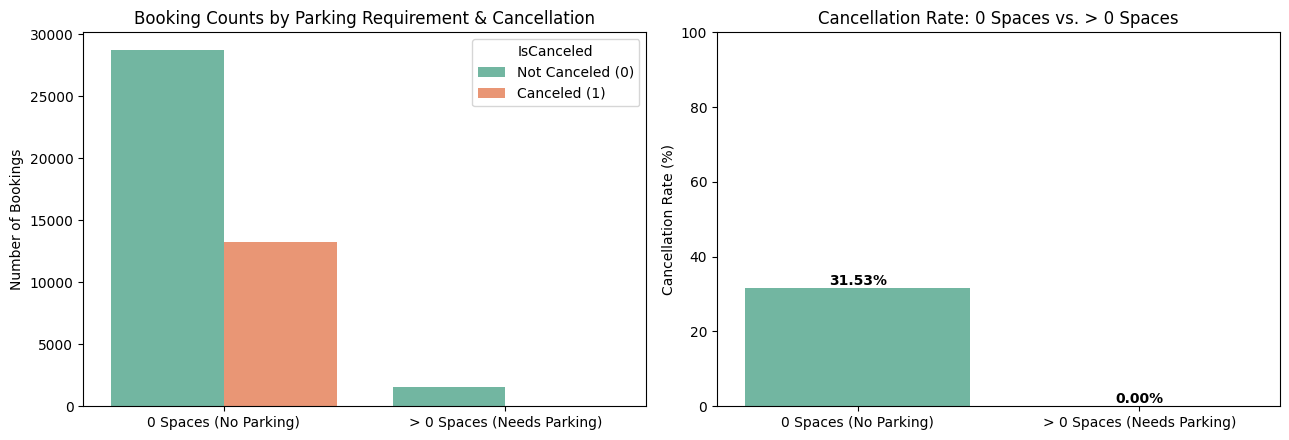

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Exact crosstab: RequiredCarParkingSpaces (0 vs >0) vs IsCanceled (0 vs 1)
parking_binary = (X_train["RequiredCarParkingSpaces"] > 0).map(
    {False: "0 Spaces (No Parking)", True: "> 0 Spaces (Needs Parking)"}
)

ct_counts = pd.crosstab(parking_binary, y_train, margins=True)
ct_props = pd.crosstab(parking_binary, y_train, normalize="index") * 100

print("=== Booking Counts: Parking Required vs. IsCanceled (Train) ===")
display(ct_counts)

print("\n=== Row Percentages (% Canceled vs. Not Canceled) ===")
display(ct_props.round(2))

# 2. Chi-square test & correlation to verify statistical relationship
ct_raw = pd.crosstab(X_train["RequiredCarParkingSpaces"] > 0, y_train)
chi2, p_val, _, _ = chi2_contingency(ct_raw)
corr = (X_train["RequiredCarParkingSpaces"] > 0).astype(int).corr(y_train)

print(f"\nChi-Square statistic: {chi2:.2f} | p-value: {p_val:.4e}")
print(f"Pearson correlation with IsCanceled: {corr:.4f}")

# 3. Visual comparison: Counts + Cancellation Rate
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(
    x=parking_binary,
    hue=y_train,
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Booking Counts by Parking Requirement & Cancellation")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of Bookings")
axes[0].legend(title="IsCanceled", labels=["Not Canceled (0)", "Canceled (1)"])

rate_df = ct_props.reset_index()
ax_bar = sns.barplot(
    data=rate_df,
    x=parking_binary.name if parking_binary.name else "RequiredCarParkingSpaces",
    y=1,
    hue=parking_binary.name if parking_binary.name else "RequiredCarParkingSpaces",
    palette="Set2",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Cancellation Rate: 0 Spaces vs. > 0 Spaces")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cancellation Rate (%)")
axes[1].set_ylim(0, 100)

for p in ax_bar.patches:
    ax_bar.annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
X_train.drop(columns=["RequiredCarParkingSpaces"], inplace=True)
X_test.drop(columns=["RequiredCarParkingSpaces"], inplace=True)

TotalOfSpecialRequests


=== TotalOfSpecialRequests Value Counts (Train) ===
TotalOfSpecialRequests
0    21638
1    14520
2     5963
3     1184
4      138
5       18
Name: count, dtype: int64

=== Cancellation Rate by TotalOfSpecialRequests (Train) ===


,total_bookings,canceled_count,cancellation_rate
TotalOfSpecialRequests,,,
0,21638,8416,0.388945
1,14520,3328,0.229201
2,5963,1255,0.210465
3,1184,208,0.175676
4,138,18,0.130435
5,18,0,0.000000


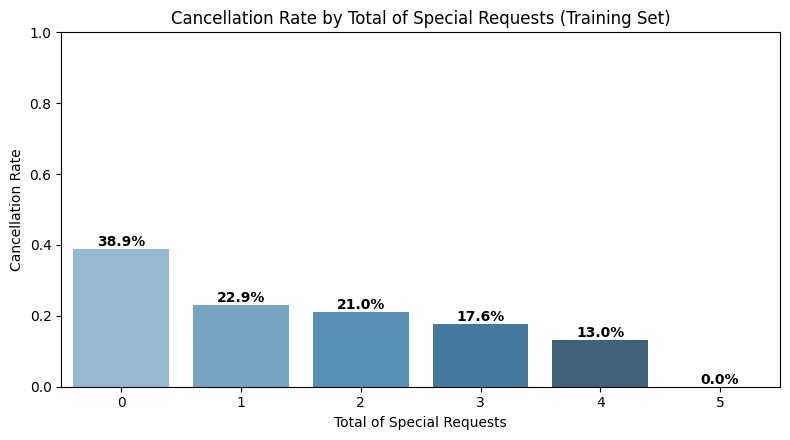

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

print("=== TotalOfSpecialRequests Value Counts (Train) ===")
print(X_train["TotalOfSpecialRequests"].value_counts().sort_index())

request_summary = (
    pd.DataFrame({
        "TotalOfSpecialRequests": X_train["TotalOfSpecialRequests"],
        "IsCanceled": y_train,
    })
    .groupby("TotalOfSpecialRequests")["IsCanceled"]
    .agg(total_bookings="count", canceled_count="sum", cancellation_rate="mean")
)

print("\n=== Cancellation Rate by TotalOfSpecialRequests (Train) ===")
display(request_summary)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    x=request_summary.index.astype(str),
    y=request_summary["cancellation_rate"],
    hue=request_summary.index.astype(str),
    palette="Blues_d",
    legend=False,
)
plt.title("Cancellation Rate by Total of Special Requests (Training Set)")
plt.xlabel("Total of Special Requests")
plt.ylabel("Cancellation Rate")
plt.ylim(0, 1.0)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def _extract_special_req_series(
    df: pd.DataFrame, candidate_cols: tuple[str, ...] = ("TotalOfSpecialRequests", "special_req")
) -> tuple[pd.Series | None, str | None]:
  for col in candidate_cols:
    if col in df.columns:
      return pd.to_numeric(df[col], errors="coerce").fillna(0), col
  return None, None


def evaluate_special_req_variant(
    X_tr: pd.DataFrame,
    X_te: pd.DataFrame,
    y_tr: pd.Series,
    y_te: pd.Series,
    mode: str,
    cap_value: int = 3,
) -> dict[str, float | int | str]:
  X_tr = X_tr.copy()
  X_te = X_te.copy()

  # Guardrail: drop any stray object/string columns if any were left unencoded
  obj_cols = X_tr.select_dtypes(include=["object", "string"]).columns.tolist()
  if obj_cols:
    X_tr = X_tr.drop(columns=obj_cols)
    X_te = X_te.drop(columns=obj_cols, errors="ignore")

  tr_sr, tr_col = _extract_special_req_series(X_tr)
  te_sr, te_col = _extract_special_req_series(X_te)

  if tr_sr is not None and te_sr is not None:
    drop_tr = [c for c in ("TotalOfSpecialRequests", "special_req", "has_special_requests") if c in X_tr.columns]
    drop_te = [c for c in ("TotalOfSpecialRequests", "special_req", "has_special_requests") if c in X_te.columns]
    X_tr = X_tr.drop(columns=drop_tr)
    X_te = X_te.drop(columns=drop_te)

    if mode == "capped":
      X_tr["special_req"] = tr_sr.clip(upper=cap_value)
      X_te["special_req"] = te_sr.clip(upper=cap_value)
      label = f"Capped at {cap_value} (0..{cap_value}+)"
    elif mode == "uncapped":
      X_tr["special_req"] = tr_sr
      X_te["special_req"] = te_sr
      label = "No capping (raw count)"
    elif mode == "flag":
      X_tr["has_special_requests"] = (tr_sr > 0).astype(int)
      X_te["has_special_requests"] = (te_sr > 0).astype(int)
      label = "Binary flag (> 0)"
    else:
      raise ValueError(f"Unsupported mode: {mode}")
  else:
    label = f"Missing special requests col ({mode})"

  model = HistGradientBoostingClassifier(
      max_iter=300,
      learning_rate=0.05,
      random_state=42,
  )
  model.fit(X_tr, y_tr)

  y_pred = model.predict(X_te)
  y_proba = model.predict_proba(X_te)[:, 1]

  return {
      "variant": label,
      "n_features": X_tr.shape[1],
      "roc_auc": roc_auc_score(y_te, y_proba),
      "f1": f1_score(y_te, y_pred),
      "accuracy": accuracy_score(y_te, y_pred),
  }


results = [
    evaluate_special_req_variant(X_train, X_test, y_train, y_test, mode="capped", cap_value=3),
    evaluate_special_req_variant(X_train, X_test, y_train, y_test, mode="uncapped"),
    evaluate_special_req_variant(X_train, X_test, y_train, y_test, mode="flag"),
]

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

               variant  n_features  roc_auc       f1  accuracy
   Capped at 3 (0..3+)          54 0.887002 0.692412  0.816595
No capping (raw count)          54 0.886424 0.691962  0.816999
     Binary flag (> 0)          54 0.884434 0.684448  0.813606


Trails


In [ ]:
import pandas as pd, numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, accuracy_score, confusion_matrix)

PATH = '/content/H2.csv'

# ---------- 1) load, remove exact duplicates (on the original columns) ----------
raw = pd.read_csv(PATH)
df = raw.drop_duplicates().copy()

# ---------- 2) cleaning and features (identical for BOTH models) ----------
for c in ['Agent', 'Company', 'Country', 'Meal', 'MarketSegment', 'ReservedRoomType', 'DepositType', 'CustomerType']:
    df[c] = df[c].fillna('Unknown').astype(str).str.strip()
df['Agent'] = df.Agent.replace('NULL', 'No agent')
df['Company_flag'] = (df.Company != 'NULL').astype(int)
df['Children'] = df.Children.fillna(0)

month_map = {m: i for i, m in enumerate(['January','February','March','April','May','June','July','August',
             'September','October','November','December'], 1)}
df['ArrivalDate'] = pd.to_datetime(dict(year=df.ArrivalDateYear,
                                        month=df.ArrivalDateMonth.map(month_map),
                                        day=df.ArrivalDateDayOfMonth))
df['month'] = df.ArrivalDate.dt.month.astype(str)

df = df[df.Adults > 0]
df['total_nights'] = df.StaysInWeekendNights + df.StaysInWeekNights
df = df[df.total_nights > 0]
df['weekend_flag'] = (df.StaysInWeekendNights > 0).astype(int)
df['total_guests'] = df.Adults + df.Children + df.Babies
df['is_room_A'] = (df.ReservedRoomType == 'A').astype(int)
df['has_prev_booking_not_canceled'] = (df.PreviousBookingsNotCanceled > 0).astype(int)
df['Meal'] = df.Meal.replace({'FB': 'HB'})

# the column being tested, as 0 / 1 / 2+ (the effect is not monotonic, so not a plain number)
df['prev_canc_cat'] = pd.cut(df.PreviousCancellations, [-1, 0, 1, np.inf],
                             labels=['0', '1', '2plus']).astype(str)

y = df.IsCanceled
train = df.ArrivalDate < '2017-01-01'                    # time-based split
X_tr, X_te, y_tr, y_te = df[train].copy(), df[~train].copy(), y[train], y[~train]

# group rare countries / agents using TRAIN counts only
top_c = X_tr.Country.value_counts().head(10).index
top_a = X_tr.Agent.value_counts()[lambda s: s >= 500].index
for p in (X_tr, X_te):
    p['Country'] = np.where(p.Country.isin(top_c), p.Country, 'Other')
    p['Agent']   = np.where(p.Agent.isin(top_a), p.Agent, 'Other')

num = ['LeadTime', 'total_nights', 'total_guests', 'weekend_flag', 'is_room_A',
       'has_prev_booking_not_canceled', 'Company_flag']
cat = ['month', 'Meal', 'Country', 'MarketSegment', 'DepositType', 'Agent', 'CustomerType']

def make(model, with_prev_canc):
    cats = cat + (['prev_canc_cat'] if with_prev_canc else [])
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats),
        ('num', StandardScaler(), num)])
    return Pipeline([('pre', pre), ('clf', model)])

models = {
    'logistic': lambda: LogisticRegression(max_iter=3000),
    'boosted' : lambda: HistGradientBoostingClassifier(max_iter=200, random_state=0),
}

# ---------- 3) train twice, compare -------# ---------- 3) train twice, compare ----------
rows, cms = [], {}
for mname, mk in models.items():
    for with_pc in (False, True):
        pipe = make(mk(), with_pc).fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        pred  = (proba >= 0.5).astype(int)
        rows.append({
            'model': mname,
            'PreviousCancellations': 'WITH' if with_pc else 'without',
            'ROC-AUC': roc_auc_score(y_te, proba),
            'PR-AUC': average_precision_score(y_te, proba),
            'F1': f1_score(y_te, pred),
            'precision': precision_score(y_te, pred),
            'recall': recall_score(y_te, pred),
            'accuracy': accuracy_score(y_te, pred),
        })
        cms[(mname, with_pc)] = confusion_matrix(y_te, pred)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
res = pd.DataFrame(rows).set_index(['model', 'PreviousCancellations']).round(4)
print(f'train rows: {len(X_tr)} | test rows: {len(X_te)} | test cancel rate: {y_te.mean():.3f}')
print(res)
for (mname, with_pc), cm in cms.items():
    print(f'\n{mname} {"WITH" if with_pc else "without"}  [[TN FP],[FN TP]]:\n{cm}')

train rows: 32869 | test rows: 19955 | test cancel rate: 0.341
                                ROC-AUC  PR-AUC      F1  precision  recall  accuracy
model    PreviousCancellations                                                      
logistic without                 0.7637  0.6040  0.4115     0.6215  0.3076    0.7002
         WITH                    0.7591  0.6023  0.4022     0.6260  0.2963    0.6998
boosted  without                 0.8035  0.6540  0.5359     0.6290  0.4668    0.7244
         WITH                    0.8007  0.6499  0.5292     0.6213  0.4608    0.7205

logistic without  [[TN FP],[FN TP]]:
[[11880  1274]
 [ 4709  2092]]

logistic WITH  [[TN FP],[FN TP]]:
[[11950  1204]
 [ 4786  2015]]

boosted without  [[TN FP],[FN TP]]:
[[11281  1873]
 [ 3626  3175]]

boosted WITH  [[TN FP],[FN TP]]:
[[11244  1910]
 [ 3667  3134]]


In [ ]:
import pandas as pd
from google.colab import files

# 1. Re-combine features and targets for the final clean sets
train_final = X_train.copy()
train_final['IsCanceled'] = y_train

test_final = X_test.copy()
test_final['IsCanceled'] = y_test

# 2. Save them to CSV files
train_final.to_csv('H2_classification_train.csv', index=False)
test_final.to_csv('H2_classification_test.csv', index=False)

print("Files saved. Starting downloads...")

# 3. Download the files to your local machine
files.download('H2_classification_train.csv')
files.download('H2_classification_test.csv')

Files saved. Starting downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>